# COPA-DATA bottle filler M7: the anomalies in the zenon data and first answers to the three research questions

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leon-adsk/copa/blob/jbt/notebooks/anomaly_findings_colab.ipynb)

**How to use it:** the notebook is saved with all its results, so for presenting you can simply scroll through it.
To run it yourself, press ▶ on the **Start** cell first; after that every step runs on its own, in any order, or use
*Run All* (about one minute). If a cell says *"Please run the Start cell first"*, Start has not run yet in this session
(for example after a restart). No login and no token are needed.

**Structure:** results at a glance → the machine and its variables → Start → steps 1-8: from the raw files to the
anomalies → step 9: what the anomalies cause → step 10: the three research questions → step 11: explore yourself.
Every step explains *what data it uses*, *what it does*, *how to read the result*, *what it shows* and *what we can say
if asked*.

**Where everything comes from:**

| what | source |
|---|---|
| data | the six TXT files from COPA-DATA in `data/txt`: zenon archive exports of filler M7, stored in our GitHub repo with Git LFS (file sizes match Andreas' shared folder). The data is simulated by COPA-DATA (task PDF slide 10: *"We use simulated data, not real-time customer data!"*) |
| meaning of columns and variables | Andreas Grün, mail 13.11.2026 (copied into `README.md` by Leon) |
| when anomalies happened (the label) | the same mail: *"There were plenty anomalies over and over again between October 29 and November 4th ~10:50; after that, so Nov 4 ~10:50 - 15:00, no anomalies occurred anymore."* |
| task, research questions, the word "online" | task PDF `PLUS_Students-Projects_Data-Science_13-10-2026.pdf`, slides 7-10 |
| software | pandas, numpy, matplotlib, scikit-learn, plotly (the project environment) |

We added no data of our own: nothing from the internet, nothing simulated or made up by us, and every column keeps its
real zenon name (for example `Sim/Global/M7_CompAir`). Andreas' label covers the export of 04.11.2026 (it ends
04.11.2026 15:00). The export of 20.11.2026 starts at 15:00; Andreas said nothing about it.

**Three terms used throughout:**
* *anomaly episode*: one anomaly occurrence, i.e. a few minutes in which a variable is outside its normal range (found in step 8);
* *clean window*: 04.11.2026 10:50-15:00, the hours in which Andreas says there were no anomalies; it shows what "normal" looks like;
* *running / stopped*: `Sim/Global/M7.Status.CurMachSpeed` = 990 or 1089 (machine running) or 0 (machine stopped).

**"Online"** appears only in step 10 (research question 2). It is the task's word for detecting anomalies *live while
the data arrives* ("online detection on the data stream", task PDF slide 9). We did not connect to anything live: we
replayed the exported file row by row.

## Results at a glance
1. **Where the anomalies are.** In the export of 04.11.2026 we find 162 anomaly episodes between 29.10. and 04.11.
   ~10:50 and none in the clean window 10:50-15:00, exactly as Andreas wrote. They appear in three variables of the
   filler: the compressed air it needs (`Sim/Global/M7_CompAir`) and the power it needs (`Sim/Global/M7_Power`) slowly
   rise above normal for a few minutes, and the fill weight (`Sim/Global/M7_FillWeight`) jumps far away from 500.
   They repeat on a 4-hour schedule and continue in the export of 20.11.2026. *(steps 3-8)*
2. **What they cause.** While a fill-weight anomaly lasts, 116 of 1,000 bottles are counted as defective instead of 46,
   about 2.5 times as many. During compressed-air and power anomalies the filler needs about 10 % more compressed air or
   9 % more power for a few minutes. The data shows no consistent link between the anomalies and machine failures, so
   in this simulation they are signs of degradation (Andreas' words), not breakdowns. *(step 9)*
3. **Research question 1: which methods work?** Even simple methods find the anomalies, with no false alarm in the
   clean window. Comparing 60-second averages with the normal range warns about 6 minutes before an anomaly reaches its
   peak. Ranking the values by how often they occur finds 59 % of the episodes (warning about 40 s before the peak),
   Isolation Forest 49 % (about 3 minutes before). Autoencoder and LSTM are not tested yet. *(step 10)*
4. **Research question 2: batch or online?** A method that only sees past data, as it would live on the data stream,
   still finds 92-100 % of what the analysis of the complete file finds, at most about 30 s later, and still gives no
   false alarm. *(step 10)*
5. **Research question 3: which archive settings?** Store the three process values every 3 s, or "on change" with a
   small hysteresis of about 0.5. At 9 s a third of the fill-weight anomalies are already missed, at 60 s three
   quarters. A hysteresis of 0.5 stores only 40-56 % of the rows and still finds at least 97 % of the episodes. *(step 10)*
6. **Open questions for COPA-DATA.** Does the export of 20.11.2026 contain anomalies on purpose? Is there a list of
   the inserted anomalies (start, end, variable) and the documented degradation model behind them? With it we could
   measure precision, recall and warning time exactly.

## The machine and its variables
**M7 is one machine: the bottle filler.** Andreas: *"Correct, it is only the (bottle) filler"* (mail 13.11.2026). The
data comes from COPA-DATA's simulation of this filler, recorded by zenon.

**The three variables with the anomalies are not production steps.** They are three measurements of the same filler,
taken at the same moment, like three gauges on one machine. zenon writes all of them every 3 s (every 10 s in the
export of 20.11.2026):

| variable | meaning (Andreas, mail 13.11.2026) | normal while running (clean window, step 3) |
|---|---|---|
| `Sim/Global/M7_CompAir` | "Current needed compressed air input of the filler" | 25.8 - 31.5 |
| `Sim/Global/M7_Power` | "Current needed power input of the filler" | 8.8 - 10.8 |
| `Sim/Global/M7_FillWeight` | "Fill Weight of the current bottle" | 495.1 - 504.6 (around 500) |

COPA-DATA gives no units, so all values are shown as recorded.

**Other variables we use:** `Sim/Global/M7.Status.CurMachSpeed` (current machine speed: 990 or 1089 = running, 0 =
stopped), the bottle counters `Sim/Global/M7.Admin.ProductData_ProcessedCount` (all filled bottles of the current
order) and `Sim/Global/M7.Admin.ProductData_DefectiveCount` (rejects / scrap / defective bottles of the current
order), and the machine state `M07.WS_Cur_State` (e.g. 128 = Operating, 1024 = Equipment Failure). Variables starting
with `Sim/Global/` hold the calculated values; `M07...` and `Converter/...` are copies written by another logic with a
short time lag (Andreas).

## Start · run this cell first
**Why it is needed:** the steps share some code: the libraries, the function that reads the six files (`raw_rows`)
and the function that builds one table per export (`wide_table`). This cell defines them, so every step after it can run
on its own. Run it once after opening the notebook, and again after a kernel restart.

**What data it uses:** none yet. Each step reads the files when it first needs them (about 20 s the first time,
afterwards they are kept in memory).

**What it does:** it looks for the copa folder with the data.
* *Kernel on your own computer* (VS Code, kernel "copa (local)"): it finds the copa folder on your disk. Nothing is
  downloaded and your latest local files are used.
* *Kernel on a Colab server* (the Colab extension in VS Code, or colab.research.google.com): that computer belongs to
  Google and cannot see your disk. So it downloads our repo from GitHub: branch `jbt` with the code, the results and the
  six data files (about 410 MB, roughly a minute, again in every new Colab session). The repo is public, so this needs
  no login and no token. It gets what was last pushed to GitHub, not local changes that are not pushed yet.

**What you see:** `Start done. Using: ...` with the place the data comes from.

In [1]:
# @title Start: run this cell first (once after opening the notebook, and again after a restart)
BRANCH = "jbt"                                        # the branch with analysis/ and results/
REPO_URL = "https://github.com/leon-adsk/copa.git"    # public repo: downloading needs no login or token

import os, sys, shutil, subprocess
from functools import cache
from pathlib import Path

try:
    import google.colab                               # can only be imported on a Colab server
    ON_COLAB = True
except ImportError:
    ON_COLAB = False

def data_ready(repo):                                 # the six data files are there (not only Git LFS placeholders)
    files = list((repo / "data" / "txt").glob("*.TXT"))
    return len(files) == 6 and all(f.stat().st_size > 1024 for f in files)

def run(cmd, **env):                                 # GIT_TERMINAL_PROMPT=0: git never asks for a password
    r = subprocess.run(cmd, capture_output=True, text=True, env={**os.environ, "GIT_TERMINAL_PROMPT": "0", **env})
    if r.returncode != 0:
        raise RuntimeError(f"download failed at: {' '.join(cmd[:5])}\n{r.stderr[-800:]}")

if ON_COLAB:                                          # Colab cannot see your computer: copy the repo from GitHub
    REPO = Path("/content/copa")
    if not data_ready(REPO):
        print("Colab server: downloading the repo from GitHub (code, results, six data files, about 410 MB) ...")
        if shutil.which("git-lfs") is None:           # git-lfs downloads the large data files
            subprocess.run("apt-get -qq update && apt-get -qq install -y git-lfs", shell=True, check=True)
        if not (REPO / ".git").exists():
            run(["git", "clone", "--depth", "1", "--branch", BRANCH, REPO_URL, str(REPO)], GIT_LFS_SKIP_SMUDGE="1")
        run(["git", "-C", str(REPO), "lfs", "install", "--local"])
        run(["git", "-C", str(REPO), "lfs", "pull", "--include", "data/txt/*"])
    WHERE = f"branch '{BRANCH}' downloaded from GitHub to the Colab server (the state last pushed)"
else:                                                 # your own computer: find the copa folder
    REPO = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "analysis" / "copa_data.py").exists()), None)
    if REPO is None:
        raise RuntimeError("copa folder not found: open this notebook from the notebooks/ folder of the copa repo")
    if not data_ready(REPO):
        raise RuntimeError("data/txt does not hold the six data files yet: run `git lfs pull` in the copa folder")
    WHERE = "the copa folder on this computer (nothing downloaded)"
os.chdir(REPO)
sys.path.insert(0, str(REPO / "analysis"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown, Image
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 250)
if ON_COLAB:                                          # interactive plotly charts in VS Code and in the browser
    import plotly.io as pio
    pio.renderers.default = "plotly_mimetype+colab"

SPEED = "Sim/Global/M7.Status.CurMachSpeed"           # 990 or 1089 = machine running, 0 = machine stopped
CLEAN_START = pd.Timestamp("2026-11-04 10:50")        # Andreas: no anomalies from ~10:50 until the end of the export (15:00)
ANOM, CLEAN = "anomalies (until 04.11. ~10:50)", "no anomalies (04.11. 10:50-15:00)"
NO_LABEL = "no statement (export 20.11.2026)"

@cache
def raw_rows():
    """Step 1: the six TXT files as delivered, with Andreas' column names, plus file name, timestamp and INVALID flag."""
    files = sorted(Path("data/txt").glob("*.TXT"))
    raw = pd.concat([pd.read_csv(f, sep=";", header=None, names=["Date", "Time", "Variable name", "value", "Status"])
                     .assign(file=f.name) for f in files], ignore_index=True)
    raw["Status"] = raw["Status"].str.strip()
    raw["timestamp"] = pd.to_datetime(raw["Date"] + " " + raw["Time"], format="%d.%m.%Y %H:%M:%S.%f")
    raw["INVALID"] = raw["Status"].str.contains("INVALID")
    return raw

@cache
def wide_table(export_code):
    """Step 2: one row per timestamp, one column per variable (real names), plus the column 'Andreas label'.
    export_code "261104" = export of 04.11.2026 (cyclic 3 s), "261120" = export of 20.11.2026 (cyclic 10 s)."""
    raw = raw_rows()
    valid = raw[~raw["INVALID"]]                                               # Andreas: ignore INVALID rows
    cyclic = valid[valid["file"].str.match(f"(FP|17){export_code}")]           # files FP... and 17...
    w = cyclic.pivot_table(index="timestamp", columns="Variable name", values="value", aggfunc="last")
    on_change = valid[valid["file"].str.match(f"07{export_code}")]             # file 07...: a row only when a value changes
    e = on_change.pivot_table(index="timestamp", columns="Variable name", values="value", aggfunc="last").sort_index().ffill()
    w = pd.merge_asof(w.reset_index(), e.reset_index(), on="timestamp").set_index("timestamp")
    w.columns.name = None
    w["Andreas label"] = np.where(w.index >= CLEAN_START, CLEAN, ANOM) if export_code == "261104" else NO_LABEL
    return w

RES = REPO / "results"; FIG = RES / "figures"; TAB = RES / "tables"
def show(name, width=1150):                           # show a figure saved by analysis/run_analysis.py
    display(Image(filename=str(FIG / name), width=width))

COPA_READY = True
print("Start done. Using:", WHERE)
print("Now run any step. Each step loads the data it needs (the first time about 20 s, afterwards instantly).")

Start done. Using: the copa folder on this computer (nothing downloaded)
Now run any step. Each step loads the data it needs (the first time about 20 s, afterwards instantly).


## Step 1 · The raw files, as delivered
**What data it uses:** all six TXT files in `data/txt`, three per export. `FP...` and `17...` store every variable at a
fixed interval (3 s in the export of 04.11.2026, 10 s in the export of 20.11.2026); `07...` stores a value only when it changes.

**What it does:** reads the files unchanged into one table with Andreas' column names (`Date; Time; Variable name; value;
Status`), adds the file name and a timestamp, and marks the rows whose Status contains `INVALID` (Andreas: ignore them).
The reading code is the function `raw_rows` in the Start cell.

**How to read the result:** table 1 = the first 8 rows exactly as in the file. Table 2 = per file: number of rows,
INVALID rows, first and last timestamp. Table 3 = which variable is in which file (number of rows). Then the README text
with Andreas' meaning of every variable.

In [2]:
if "COPA_READY" not in globals(): raise RuntimeError("Please run the Start cell (top of the notebook) first.")
raw = raw_rows()                     # the six files as delivered (code: raw_rows in the Start cell)
display(raw.head(8))
display(raw.groupby("file").agg(rows=("value", "size"), INVALID_rows=("INVALID", "sum"),
                                first=("timestamp", "min"), last=("timestamp", "max")))

,Date,Time,Variable name,value,Status,file,timestamp,INVALID
0,29.10.2026,06:53:09.574,M07.WS_Cur_State,262144.0,SPONT T_STD_E T_EXTERN T_STD,07261104141229_07.TXT,2026-10-29 06:53:09.574,False
1,29.10.2026,06:53:11.543,M07.WS_Cur_State,128.0,SPONT T_STD_E T_EXTERN T_STD,07261104141229_07.TXT,2026-10-29 06:53:11.543,False
2,29.10.2026,06:58:38.317,M07.WS_Cur_State,131072.0,SPONT T_STD_E T_EXTERN T_STD,07261104141229_07.TXT,2026-10-29 06:58:38.317,False
3,29.10.2026,06:58:39.417,M07.WS_Cur_State,8.0,SPONT T_STD_E T_EXTERN T_STD,07261104141229_07.TXT,2026-10-29 06:58:39.417,False
4,29.10.2026,06:53:11.543,M07.WS_Cur_Prog,1.0,SPONT T_STD_E T_EXTERN T_STD,07261104141229_07.TXT,2026-10-29 06:53:11.543,False
5,29.10.2026,07:00:00.000,M07.WS_Cur_State,8.0,SPONT T_STD_E T_EXTERN T_STD,07261104141229_07.TXT,2026-10-29 07:00:00.000,False
6,29.10.2026,07:00:24.535,M07.WS_Cur_State,262144.0,SPONT T_STD_E T_EXTERN T_STD,07261104141229_07.TXT,2026-10-29 07:00:24.535,False
7,29.10.2026,07:00:26.505,M07.WS_Cur_State,128.0,SPONT T_STD_E T_EXTERN T_STD,07261104141229_07.TXT,2026-10-29 07:00:26.505,False


,rows,INVALID_rows,first,last
file,,,,
07261104141229_07.TXT,4673,0,2026-10-29 06:53:09.574,2026-11-04 15:00:00
07261120103434_07.TXT,11865,6,2026-11-04 15:00:00.000,2026-11-20 11:00:00
17261104141251_17.TXT,730242,0,2026-10-29 06:50:00.000,2026-11-04 15:00:00
17261120103538_17.TXT,547204,1088,2026-11-04 15:00:00.000,2026-11-20 11:00:00
FP261104141238_FP.TXT,2007441,0,2026-10-29 06:50:00.000,2026-11-04 15:00:00
FP261120103526_FP.TXT,1504811,2992,2026-11-04 15:00:00.000,2026-11-20 11:00:00


In [3]:
if "COPA_READY" not in globals(): raise RuntimeError("Please run the Start cell (top of the notebook) first.")
# which variable is in which file (number of rows)
raw = raw_rows()
display(raw.pivot_table(index="Variable name", columns="file", values="value", aggfunc="size", fill_value=0))

file,07261104141229_07.TXT,07261120103434_07.TXT,17261104141251_17.TXT,17261120103538_17.TXT,FP261104141238_FP.TXT,FP261120103526_FP.TXT
Variable name,,,,,,
Converter/Global/M07.Power,0,0,182557,136801,0,0
M07.WS_Cur_Mach_Spd,0,0,182561,136801,0,0
M07.WS_Cur_Mode,153,387,0,0,0,0
M07.WS_Cur_Prog,518,1272,0,0,0,0
M07.WS_Cur_State,4002,10206,0,0,0,0
M07.WS_Good_packages,0,0,182563,136801,0,0
M07.WS_Tot_Packages,0,0,182561,136801,0,0
Sim/Global/M7.Admin.ProductData_DefectiveCount,0,0,0,0,182499,136801
Sim/Global/M7.Admin.ProductData_ProcessedCount,0,0,0,0,182486,136801


In [4]:
if "COPA_READY" not in globals(): raise RuntimeError("Please run the Start cell (top of the notebook) first.")
# meaning of the variables: README.md of the repo (copied from Andreas' mail)
readme = Path("README.md").read_text()
print(readme[readme.index("## Variable Descriptions"):readme.index("## Confidentiality")])

## Variable Descriptions
1. M07.WS_Good_packages: Count of '"good" filled bottles (this excludes rejects / scrap / defective bottles) for current order
2. M07.WS_Tot_Packages: Count of total filled bottles for current order
3. M07.WS_Cur_Mach_Spd:  Current machine speed
4. Sim/Global/M7_FillWeight: Fill Weight of the current bottle
5. Sim/Global/M7.Admin.ProductData_DefectiveCount: Count of excludes rejects / scrap / defective bottles for current order
6. Converter/Global/M07.Power: Current needed power input of the filler
7. Sim/Global/M7_Energy_incremental: Accumulated power consumption of the filler for current
8. Sim/Global/M7_CompAir_incremental: Accumulated compressed air consumption of the filler for current
9. Sim/Global/M7_CompAir: Current needed compressed air input of the filler
10. Sim/Global/M7_Power: same as 6.)
11. Sim/Global/M7.Status.CurMachSpeed: same as 3.) 
12. Sim/Global/M7.Status.MachSpeed: Target or nominal speed
13. Sim/Global/M7.Status.StateCurrent: Current sta

**What it shows:**
* Export of 04.11.2026: 29.10.2026 06:50 to 04.11.2026 15:00. Files `FP...` 2,007,441 rows, `17...` 730,242, `07...` 4,673. No INVALID rows.
* Export of 20.11.2026: 04.11.2026 15:00 to 20.11.2026 11:00. Files `FP...` 1,504,811 rows, `17...` 547,204, `07...` 11,865.
  4,086 INVALID rows, all on 04.11. between 15:00:10 and 15:45:20.
* The two exports follow each other without overlap. `FP...` holds the 11 `Sim/Global/M7...` variables, `17...` four
  `M07...`/`Converter...` variables, `07...` the machine-state variables `M07.WS_Cur_State`, `M07.WS_Cur_Prog`, `M07.WS_Cur_Mode`.

**What we can say:** *"We used the six raw zenon files exactly as COPA-DATA delivered them: two consecutive exports of
filler M7 (29.10.-04.11. at 3 s, 04.11.-20.11. at 10 s) with 18 variables, and we only dropped the rows marked INVALID,
as Andreas asked."*

## Step 2 · One row per timestamp, real variable names as columns
**What data it uses:** the valid rows from step 1.

**What it does:** for each export it puts the two cyclic files (`FP...` and `17...`, same timestamps) side by side:
one row per timestamp, one column per variable, with the real variable names. The on-change file `07...` only has a row
when a state changes, so its last value is carried forward. It adds the column `Andreas label` from his mail:
before 04.11. 10:50 "anomalies", 10:50-15:00 "no anomalies", the export of 20.11.2026 "no statement".
The code is the function `wide_table` in the Start cell; steps 3-7 and 10 use these two tables.

**How to read the result:** the printed numbers are (rows, columns) of the two tables; the table below shows the rows of
30.10.2026 20:14:00-20:14:15 (one row every 3 s), one column per variable.

In [5]:
if "COPA_READY" not in globals(): raise RuntimeError("Please run the Start cell (top of the notebook) first.")
w1 = wide_table("261104")            # export of 04.11.2026 (cyclic 3 s); code: wide_table in the Start cell
w2 = wide_table("261120")            # export of 20.11.2026 (cyclic 10 s)
print("export of 04.11.2026:", w1.shape, "   export of 20.11.2026:", w2.shape, "   (rows, columns)")
display(w1.loc["2026-10-30 20:14:00":"2026-10-30 20:14:15"])

export of 04.11.2026: (182576, 19)    export of 20.11.2026: (136529, 19)    (rows, columns)


,Converter/Global/M07.Power,M07.WS_Cur_Mach_Spd,M07.WS_Good_packages,M07.WS_Tot_Packages,Sim/Global/M7.Admin.ProductData_DefectiveCount,Sim/Global/M7.Admin.ProductData_ProcessedCount,Sim/Global/M7.Status.CurMachSpeed,Sim/Global/M7.Status.MachSpeed,Sim/Global/M7.Status.StateCurrent,Sim/Global/M7.Status.UnitModeCurrent,Sim/Global/M7_CompAir,Sim/Global/M7_CompAir_incremental,Sim/Global/M7_Energy_incremental,Sim/Global/M7_FillWeight,Sim/Global/M7_Power,M07.WS_Cur_Mode,M07.WS_Cur_Prog,M07.WS_Cur_State,Andreas label
timestamp,,,,,,,,,,,,,,,,,,,
2026-10-30 20:14:00,10.7,990.0,32350.0,35603.0,3253.0,35626.0,990.0,1000.0,6.0,1.0,28.6,748.5,294.0,500.5,10.7,8.0,1.0,128.0,anomalies (until 04.11. ~10:50)
2026-10-30 20:14:03,10.5,990.0,32397.0,35652.0,3256.0,35675.0,990.0,1000.0,6.0,1.0,30.6,748.5,294.0,498.4,10.2,8.0,1.0,128.0,anomalies (until 04.11. ~10:50)
2026-10-30 20:14:06,10.6,990.0,32446.0,35702.0,3257.0,35725.0,990.0,1000.0,6.0,1.0,33.2,748.5,294.0,499.7,9.8,8.0,1.0,128.0,anomalies (until 04.11. ~10:50)
2026-10-30 20:14:09,10.0,990.0,32485.0,35743.0,3258.0,35776.0,990.0,1000.0,6.0,1.0,32.3,748.5,294.0,500.7,9.1,8.0,1.0,128.0,anomalies (until 04.11. ~10:50)
2026-10-30 20:14:12,10.5,990.0,32533.0,35792.0,3260.0,35824.0,990.0,1000.0,6.0,1.0,29.2,748.6,294.0,500.4,10.0,8.0,1.0,128.0,anomalies (until 04.11. ~10:50)
2026-10-30 20:14:15,9.7,990.0,32590.0,35850.0,3261.0,35875.0,990.0,1000.0,6.0,1.0,31.9,748.6,294.0,501.1,10.7,8.0,1.0,128.0,anomalies (until 04.11. ~10:50)


**What it shows:** the export of 04.11.2026 has 182,576 rows (one every 3 s) and 19 columns (18 variables + the label);
the export of 20.11.2026 has 136,529 rows (one every 10 s, INVALID rows left out). In the example rows the machine runs
(`Sim/Global/M7.Status.CurMachSpeed` = 990).

**What we can say:** *"We turned the files into one table per export, with one row per time step and one column per
variable, so that all variables can be compared at the same moment."*

## Step 3 · Which variables are different when Andreas says "anomalies"?
**What data it uses:** the export of 04.11.2026, the only one with a label: 148.0 hours before 04.11. 10:50
("anomalies") and 4.17 hours after ("no anomalies").

**What it does:** for each process variable it takes the lowest and the highest value in each period, separately for
`Sim/Global/M7.Status.CurMachSpeed` = 990 (machine running) and = 0 (machine stopped). Running and stopped must be
separated because the values are completely different (compressed air about 29 when running, about 2 when stopped).
The second part counts how often each state of `M07.WS_Cur_State` is entered per hour in both periods.

**How to read the result:** in the first two tables the rows are variable + min/max and the columns are the two periods.
If the "anomalies" column has a clearly higher max or lower min than the "no anomalies" column, that variable behaves
differently while Andreas says there are anomalies. In the third table the rows are the state numbers of
`M07.WS_Cur_State` (meaning in the README, e.g. 128 = Operating, 1024 = Equipment Failure, 8 = Lack) and the numbers
are entries per hour.

In [6]:
if "COPA_READY" not in globals(): raise RuntimeError("Please run the Start cell (top of the notebook) first.")
w1 = wide_table("261104")
process = ["Sim/Global/M7_CompAir", "Sim/Global/M7_Power", "Converter/Global/M07.Power", "Sim/Global/M7_FillWeight"]
for speed in [990, 0]:
    t = w1[w1[SPEED] == speed].groupby("Andreas label")[process].agg(["min", "max"]).T.round(1)
    display(Markdown(f"**{SPEED} = {speed}**"))
    display(t)

**Sim/Global/M7.Status.CurMachSpeed = 990**

Andreas label                   anomalies (until 04.11. ~10:50)  no anomalies (04.11. 10:50-15:00)
Sim/Global/M7_CompAir      min                             25.8                               25.8
                           max                             38.6                               31.5
Sim/Global/M7_Power        min                              8.8                                8.8
                           max                             12.7                               10.8
Converter/Global/M07.Power min                              3.6                                3.6
                           max                             12.7                               10.8
Sim/Global/M7_FillWeight   min                            482.4                              495.1
                           max                            517.7                              504.6

**Sim/Global/M7.Status.CurMachSpeed = 0**

Andreas label                   anomalies (until 04.11. ~10:50)  no anomalies (04.11. 10:50-15:00)
Sim/Global/M7_CompAir      min                              1.8                                1.8
                           max                              9.4                                2.2
Sim/Global/M7_Power        min                              3.6                                3.6
                           max                              4.4                                4.4
Converter/Global/M07.Power min                              3.6                                3.6
                           max                             21.7                               10.6
Sim/Global/M7_FillWeight   min                              0.0                              496.9
                           max                            514.5                              502.6

In [7]:
if "COPA_READY" not in globals(): raise RuntimeError("Please run the Start cell (top of the notebook) first.")
# machine states (file 07, on change): do they differ? entries per hour
raw, w1 = raw_rows(), wide_table("261104")
st = raw[~raw["INVALID"] & raw["file"].str.match("07261104") & (raw["Variable name"] == "M07.WS_Cur_State")]
hours = {ANOM: (CLEAN_START - w1.index.min()).total_seconds() / 3600, CLEAN: 4 + 10 / 60}
st = st.assign(label=np.where(st["timestamp"] >= CLEAN_START, CLEAN, ANOM))
per_h = st.groupby(["value", "label"]).size().unstack(fill_value=0)
display((per_h / pd.Series(hours)).round(2).rename_axis("M07.WS_Cur_State value"))

label,anomalies (until 04.11. ~10:50),no anomalies (04.11. 10:50-15:00)
M07.WS_Cur_State value,,
2.0,0.59,0.72
8.0,3.36,2.64
16.0,0.14,0.00
128.0,6.95,7.68
1024.0,1.83,2.40
8192.0,1.82,2.40
32768.0,0.61,0.48
65536.0,1.74,2.40
131072.0,4.22,3.36


**What it shows:** while the machine runs, `Sim/Global/M7_CompAir` never goes above 31.5 after 10:50 but reaches 38.6
before; `Sim/Global/M7_Power` (and its copy `Converter/Global/M07.Power`) stays at or below 10.8 after 10:50 but reaches
12.7 before; `Sim/Global/M7_FillWeight` stays within 495.1-504.6 after 10:50 but ranges from 482.4 to 517.7 before.
While the machine stands, `Sim/Global/M7_CompAir` stays at or below 2.2 after 10:50 but reaches 9.4 before.
The machine states occur at similar rates in both periods (e.g. 1024 Equipment Failure 1.83 vs. 2.40 per hour, 128 Operating
6.95 vs. 7.68 per hour): stops and failures are normal operation here, not the anomaly. The clean window is only about
4 hours, so its range is an estimate; the rules in step 4 therefore add a small margin.
(`Converter/Global/M07.Power` is a copy of `Sim/Global/M7_Power` written by another logic with a time lag, per Andreas'
mail; that is why it can still show running values right after the machine stopped.)

**What we can say:** *"Comparing Andreas' anomaly period with his anomaly-free window, three variables behave
differently: compressed air (`Sim/Global/M7_CompAir`) and power (`Sim/Global/M7_Power`) go higher than ever seen in the
clean window, and the fill weight (`Sim/Global/M7_FillWeight`) jumps far outside its normal range. The machine states do
not change."*

## Step 4 · Simple rules from these ranges, counted per day
**What data it uses:** both exports (the tables of step 2).

**What it does:** turns the ranges of step 3 into four yes/no rules, each a little beyond the clean-window range:
`Sim/Global/M7_CompAir` > 33 while running, `Sim/Global/M7_CompAir` > 2.3 while stopped, `Sim/Global/M7_Power` > 11.4
while running, `Sim/Global/M7_FillWeight` < 493.6 or > 506.1 while running (running = `CurMachSpeed` 990 or 1089).
Then it counts per day how many rows break each rule.

**How to read the result:** rows = days (04.11. split into before 10:50 and 10:50-15:00), columns = the four rules,
numbers = rows that break the rule on that day. One row is 3 s in the export of 04.11.2026 and 10 s in the export of
20.11.2026, so counts of the two exports are not directly comparable. The last table lists the actual rows of
30.10.2026 20:00-20:30 that break the first rule.

In [8]:
if "COPA_READY" not in globals(): raise RuntimeError("Please run the Start cell (top of the notebook) first.")
def rule_hits(w):
    run, stop = w[SPEED].isin([990, 1089]), w[SPEED] == 0
    hits = pd.DataFrame({
        "Sim/Global/M7_CompAir > 33 (running)": run & (w["Sim/Global/M7_CompAir"] > 33),
        "Sim/Global/M7_CompAir > 2.3 (stopped)": stop & (w["Sim/Global/M7_CompAir"] > 2.3),
        "Sim/Global/M7_Power > 11.4 (running)": run & (w["Sim/Global/M7_Power"] > 11.4),
        "Sim/Global/M7_FillWeight < 493.6 or > 506.1 (running)":
            run & ((w["Sim/Global/M7_FillWeight"] < 493.6) | (w["Sim/Global/M7_FillWeight"] > 506.1)),
    })
    day = w.index.strftime("%Y-%m-%d").where(w["Andreas label"] != CLEAN, "2026-11-04 10:50-15:00")
    return hits.groupby(day).sum()

display(Markdown("**Export of 04.11.2026** (rows per day; the last row is Andreas' window without anomalies)"))
display(rule_hits(wide_table("261104")))
display(Markdown("**Export of 20.11.2026** (no statement from Andreas)"))
display(rule_hits(wide_table("261120")))

**Export of 04.11.2026** (rows per day; the last row is Andreas' window without anomalies)

,Sim/Global/M7_CompAir > 33 (running),Sim/Global/M7_CompAir > 2.3 (stopped),Sim/Global/M7_Power > 11.4 (running),Sim/Global/M7_FillWeight < 493.6 or > 506.1 (running)
timestamp,,,,
2026-10-29,74,74,53,49
2026-10-30,133,509,113,78
2026-10-31,247,243,122,88
2026-11-01,79,636,60,73
2026-11-02,134,604,42,81
2026-11-03,113,521,65,54
2026-11-04,41,201,49,46
2026-11-04 10:50-15:00,0,0,0,0


**Export of 20.11.2026** (no statement from Andreas)

,Sim/Global/M7_CompAir > 33 (running),Sim/Global/M7_CompAir > 2.3 (stopped),Sim/Global/M7_Power > 11.4 (running),Sim/Global/M7_FillWeight < 493.6 or > 506.1 (running)
timestamp,,,,
2026-11-04,0,45,0,5
2026-11-05,46,114,21,16
2026-11-06,41,124,29,17
2026-11-07,56,124,20,19
2026-11-08,63,101,40,11
2026-11-09,20,127,15,19
2026-11-10,54,103,9,25
2026-11-11,45,127,23,23
2026-11-12,49,85,16,18


In [9]:
if "COPA_READY" not in globals(): raise RuntimeError("Please run the Start cell (top of the notebook) first.")
# the rows themselves: Sim/Global/M7_CompAir > 33 while running, on 30.10.2026
w1 = wide_table("261104")
hit = w1[w1[SPEED].isin([990, 1089]) & (w1["Sim/Global/M7_CompAir"] > 33)]
display(hit.loc["2026-10-30 20:00":"2026-10-30 20:30", [SPEED, "Sim/Global/M7_CompAir", "Andreas label"]].head(15))

,Sim/Global/M7.Status.CurMachSpeed,Sim/Global/M7_CompAir,Andreas label
timestamp,,,
2026-10-30 20:14:06,990.0,33.2,anomalies (until 04.11. ~10:50)
2026-10-30 20:14:51,990.0,33.1,anomalies (until 04.11. ~10:50)
2026-10-30 20:14:54,990.0,33.7,anomalies (until 04.11. ~10:50)
2026-10-30 20:15:00,990.0,33.6,anomalies (until 04.11. ~10:50)
2026-10-30 20:15:21,990.0,33.4,anomalies (until 04.11. ~10:50)
2026-10-30 20:15:42,990.0,33.7,anomalies (until 04.11. ~10:50)
2026-10-30 20:15:45,990.0,33.6,anomalies (until 04.11. ~10:50)
2026-10-30 20:15:48,990.0,33.3,anomalies (until 04.11. ~10:50)
2026-10-30 20:16:03,990.0,33.8,anomalies (until 04.11. ~10:50)


**What it shows:** in the export of 04.11.2026 every day from 29.10. until 04.11. 10:50 has rows breaking every rule
(e.g. 31.10.: 247 / 243 / 122 / 88 rows), and 04.11. 10:50-15:00 has 0 for all four rules, exactly as Andreas wrote.
The export of 20.11.2026 also has hits on every day. On 30.10.2026 between 20:12 and 20:21 the compressed air is above 33
again and again while the machine runs at 990.

**What we can say:** *"Four simple threshold rules on real variables reproduce Andreas' statement: they fire every day
before 04.11. 10:50 and never in his anomaly-free window. The same rules also fire on every day of the second export,
which Andreas has not commented on yet."*

## Step 5 · See it: same variable, same scale, 20 minutes without and with anomalies
**What data it uses:** the export of 04.11.2026: for each of the three variables one 20-minute window before 10:50 and
the same 20 minutes of the clean window (04.11.2026 12:00-12:20).

**What it does:** draws the variable over time. Blue = machine running, grey = machine stopped, green band = range
seen while running in 10:50-15:00, red dots = running values outside that band.

**How to read the result:** x-axis = time of day; y-axis = the value of the variable as recorded (COPA-DATA gives no
units). Left column = no anomalies, right column = anomalies; each row uses the same scale left and right, so you can
compare directly. The printed lines count the red dots per window.

**Why 20 minutes:** one anomaly episode lasts a few minutes (median 8.1 min for compressed air, 5.4 min for power and
5.5 min for fill weight; the longest 11.4 min, see step 8). 20 minutes show one whole episode plus normal minutes before
and after it, with every single value visible (one every 3 s, about 400 values). A whole day would squeeze the episode
into a thin spike, and all six days hide it completely (that is why step 6 uses the highest value per 10 minutes). The
20 minutes are only the zoom of the picture; no result depends on them. The three examples are episodes from the list
of step 8: 30.10. 20:14-20:22, 03.11. 06:45-06:54 and 04.11. 10:03-10:13. Any other window can be drawn in step 11.

Sim/Global/M7_CompAir, 04.11.2026 12:00: 0 running values outside the green band
Sim/Global/M7_CompAir, 30.10.2026 20:05: 118 running values outside the green band
Sim/Global/M7_Power, 04.11.2026 12:00: 0 running values outside the green band
Sim/Global/M7_Power, 03.11.2026 06:38: 70 running values outside the green band
Sim/Global/M7_FillWeight, 04.11.2026 12:00: 0 running values outside the green band
Sim/Global/M7_FillWeight, 04.11.2026 10:00: 24 running values outside the green band


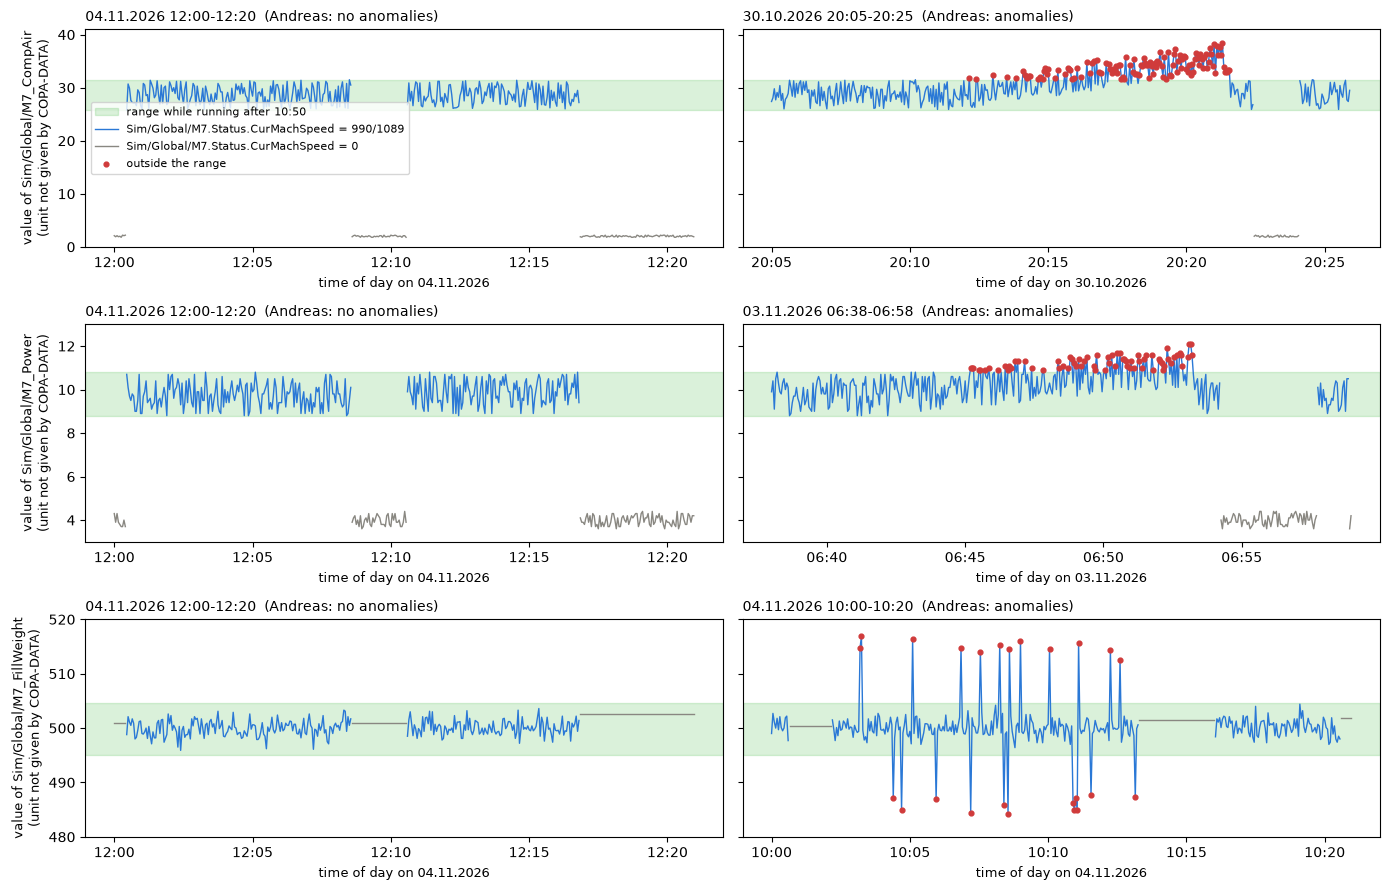

In [10]:
if "COPA_READY" not in globals(): raise RuntimeError("Please run the Start cell (top of the notebook) first.")
w1 = wide_table("261104")
examples = {"Sim/Global/M7_CompAir": ("2026-10-30 20:05", "2026-10-30 20:25", (25.8, 31.5), (0, 41)),
            "Sim/Global/M7_Power": ("2026-11-03 06:38", "2026-11-03 06:58", (8.8, 10.8), (3, 13)),
            "Sim/Global/M7_FillWeight": ("2026-11-04 10:00", "2026-11-04 10:20", (495.1, 504.6), (480, 520))}
fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharey="row")
for i, (var, (a, b, band, ylim)) in enumerate(examples.items()):
    for j, (t0, t1, title) in enumerate([("2026-11-04 12:00", "2026-11-04 12:20", "Andreas: no anomalies"), (a, b, "Andreas: anomalies")]):
        s = w1.loc[t0:t1]
        run = s[SPEED].isin([990, 1089])
        ax = axes[i, j]
        ax.axhspan(*band, color="#0ca30c", alpha=0.15, label="range while running after 10:50")
        ax.plot(s.index, s[var].where(run), color="#2a78d6", lw=1, label=f"{SPEED} = 990/1089")
        ax.plot(s.index, s[var].where(~run), color="#898781", lw=1, label=f"{SPEED} = 0")
        out = run & ((s[var] < band[0]) | (s[var] > band[1]))
        ax.scatter(s.index[out], s.loc[out, var], s=12, color="#d03b3b", zorder=3, label="outside the range")
        ax.set_ylim(*ylim)
        ax.set_ylabel(f"value of {var}\n(unit not given by COPA-DATA)" if j == 0 else "", fontsize=9)
        ax.set_xlabel(f"time of day on {pd.Timestamp(t0):%d.%m.%Y}", fontsize=9)
        ax.set_title(f"{pd.Timestamp(t0):%d.%m.%Y %H:%M}-{pd.Timestamp(t1):%H:%M}  ({title})", loc="left", fontsize=10)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
        print(f"{var}, {pd.Timestamp(t0):%d.%m.%Y %H:%M}: {int(out.sum())} running values outside the green band")
axes[0, 0].legend(loc="center left", fontsize=8)
plt.tight_layout(); plt.show()

**What it shows:** on the left all values stay inside the green band. On the right `Sim/Global/M7_CompAir` creeps up
from about 29 to about 38 within roughly 8 minutes (30.10.2026 20:13-20:21) and then the machine stops;
`Sim/Global/M7_Power` creeps up from about 10 to about 12 (03.11.2026 06:45-06:53); `Sim/Global/M7_FillWeight` jumps to
about 485 or 515 many times within 10 minutes (04.11.2026 10:03-10:13). The slow rise of compressed air and power fits
Andreas' remark that there "should be anomalies that show signs of degradation" (mail 13.11.).

**What we can say:** *"An anomaly is not one wrong value but a few minutes in which compressed air or power slowly rise
above their normal level, or the fill weight jumps far off its target, while the machine is running."*

## Step 6 · Where they lie over all days
**What data it uses:** both exports back to back, all days from 29.10.2026 06:50 to 20.11.2026 11:00.

**What it does:** a plot of all 180,000 values per variable would hide a 10-minute episode in the noise. So it cuts the
time into 10-minute blocks (3,194 blocks) and keeps one number per block: the highest value of the variable in those
10 minutes (for the fill weight also the lowest, because it can be too high or too low). Only rows with the machine
running are used (second panel: machine stopped). Blocks beyond the rule of step 4 are marked red.

**How to read the result:** one panel per variable. x-axis = date; one point = one 10-minute block. y-axis = **not a
count**: it is the highest value the variable reached in that block (fill weight: highest and lowest value). The
horizontal line is the rule of step 4. Example: in the block 30.10.2026 20:10-20:20 the highest value of
`Sim/Global/M7_CompAir` is 37.2 and in 20:20-20:30 it is 38.4, both above the line at 33 and therefore red; the block
before (20:00-20:10: 31.4) and the block after (20:30-20:40: 31.5) stay below it. Background: light red = export of
04.11.2026 before 10:50 (Andreas: anomalies), green = 10:50-15:00 (Andreas: no anomalies), white = export of
20.11.2026 (no statement).

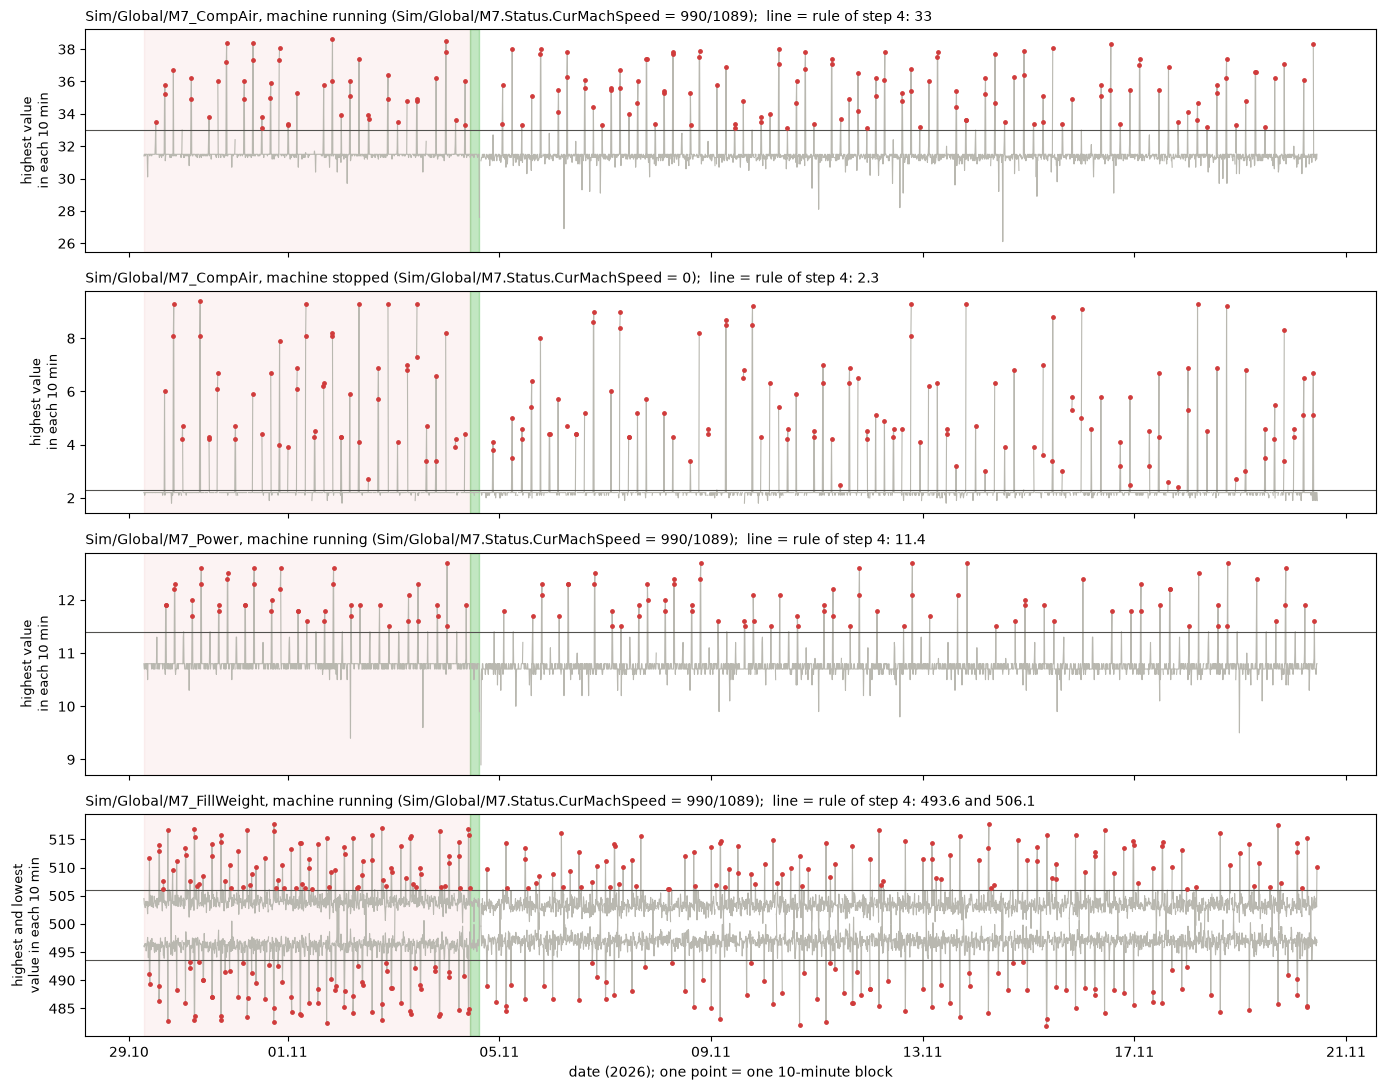

In [11]:
if "COPA_READY" not in globals(): raise RuntimeError("Please run the Start cell (top of the notebook) first.")
w1, w2 = wide_table("261104"), wide_table("261120")
both = pd.concat([w1, w2[w2.index > w1.index.max()]])       # both exports back to back: 29.10. 06:50 - 20.11. 11:00
run, stop = both[SPEED].isin([990, 1089]), both[SPEED] == 0
panels = [("Sim/Global/M7_CompAir", "running", run, [33]),  # variable, machine, rows used, rule line(s) of step 4
          ("Sim/Global/M7_CompAir", "stopped", stop, [2.3]),
          ("Sim/Global/M7_Power", "running", run, [11.4]),
          ("Sim/Global/M7_FillWeight", "running", run, [493.6, 506.1])]
fig, axes = plt.subplots(len(panels), 1, figsize=(14, 11), sharex=True)
for ax, (var, machine, rows, lines) in zip(axes, panels):
    values = both[var].where(rows)
    ax.axvspan(w1.index.min(), CLEAN_START, color="#d03b3b", alpha=0.06)
    ax.axvspan(CLEAN_START, pd.Timestamp("2026-11-04 15:00"), color="#0ca30c", alpha=0.25)
    highest = values.resample("10min").max()                 # highest value in each 10-minute block
    ax.plot(highest.index, highest, color="#b9b8b0", lw=0.8)
    red = highest > max(lines)
    ax.scatter(highest.index[red], highest[red], s=6, color="#d03b3b", zorder=3)
    ylabel = "highest value\nin each 10 min"
    if len(lines) == 2:                                      # fill weight: too low is an anomaly as well
        lowest = values.resample("10min").min()              # lowest value in each 10-minute block
        ax.plot(lowest.index, lowest, color="#b9b8b0", lw=0.8)
        red = lowest < min(lines)
        ax.scatter(lowest.index[red], lowest[red], s=6, color="#d03b3b", zorder=3)
        ylabel = "highest and lowest\nvalue in each 10 min"
    for line in lines:
        ax.axhline(line, color="#52514e", lw=0.8)
    speed = "990/1089" if machine == "running" else "0"
    ax.set_title(f"{var}, machine {machine} ({SPEED} = {speed});  line = rule of step 4: {' and '.join(map(str, lines))}",
                 loc="left", fontsize=10)
    ax.set_ylabel(ylabel, fontsize=9)
axes[-1].set_xlabel("date (2026); one point = one 10-minute block")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
plt.tight_layout(); plt.show()

**What it shows:** red dots appear on every day of the red period, none in the green window, and again on every day of
the export of 20.11.2026. They come in regular bursts, several per day, not as one long fault.

**What we can say:** *"Seen at 10-minute resolution, the anomalies are regular peaks above the normal level throughout
29.10.-04.11. 10:50, with none in Andreas' clean window; the same pattern continues in the second export."*

## Step 7 · Your idea: rank the values by how often they occur
**What data it uses:** `Sim/Global/M7_FillWeight` while the machine runs (`CurMachSpeed` 990 or 1089), export of 04.11.2026.

**What it does:** counts how often each value occurs (the "descending list"), marks values that occur in fewer than 1
of 10,000 rows as *rare*, and shows where in time the rare rows are. It does **not** use Andreas' label (unsupervised);
the label is only used afterwards to check the result. Only running rows are ranked, otherwise every stop would look rare.

**How to read the result:** table 1 = the 10 most frequent values (rows, share of all running rows); table 2 = the 10
rarest; the printed counts = rare rows per Andreas label; the plot: x-axis = date, y-axis = value of
`Sim/Global/M7_FillWeight`, grey = all values, red = rare values, green band = Andreas' clean window.

**Sim/Global/M7_FillWeight: 320 different values. Most frequent:**

,rows,share of rows %,"rare (< 1 in 10,000 rows)"
Sim/Global/M7_FillWeight,,,
500.5,3305,2.6801,False
500.1,3290,2.6680,False
499.6,3234,2.6226,False
500.4,3205,2.5990,False
500.3,3160,2.5625,False
499.8,3151,2.5552,False
500.2,3141,2.5471,False
500.7,3098,2.5123,False
499.9,3098,2.5123,False


**Rarest:**

,rows,share of rows %,"rare (< 1 in 10,000 rows)"
Sim/Global/M7_FillWeight,,,
488.7,1,0.0008,True
488.4,1,0.0008,True
491.0,1,0.0008,True
515.0,1,0.0008,True
506.6,1,0.0008,True
490.6,1,0.0008,True
490.8,1,0.0008,True
516.9,1,0.0008,True
516.0,1,0.0008,True


208 rare values, 557 rare rows
rare rows per Andreas label:
Andreas label
anomalies (until 04.11. ~10:50)    557
Name: count, dtype: int64


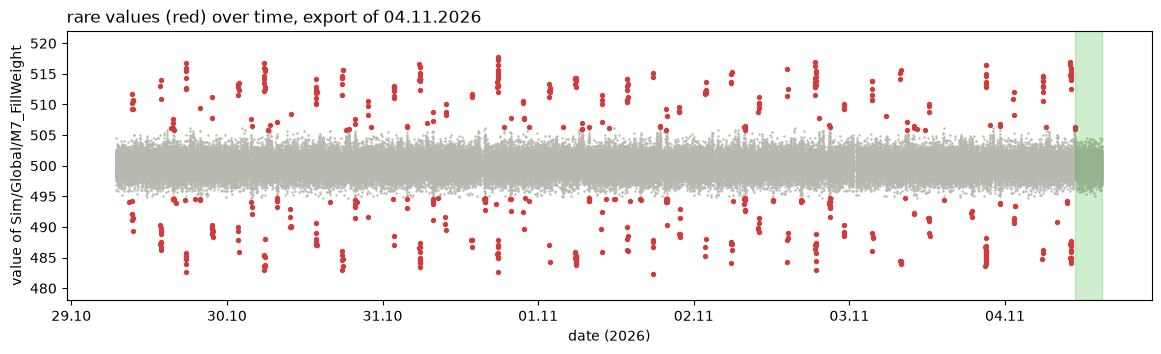

In [12]:
if "COPA_READY" not in globals(): raise RuntimeError("Please run the Start cell (top of the notebook) first.")
w1 = wide_table("261104")
var = "Sim/Global/M7_FillWeight"
vals = w1.loc[w1[SPEED].isin([990, 1089]), var].round(1)
ranking = vals.value_counts().rename("rows").to_frame()
ranking["share of rows %"] = (100 * ranking["rows"] / ranking["rows"].sum()).round(4)
ranking["rare (< 1 in 10,000 rows)"] = ranking["share of rows %"] < 0.01
display(Markdown(f"**{var}: {len(ranking)} different values. Most frequent:**")); display(ranking.head(10))
display(Markdown("**Rarest:**")); display(ranking.tail(10))
rare_values = set(ranking.index[ranking["rare (< 1 in 10,000 rows)"]])
is_rare = w1[SPEED].isin([990, 1089]) & w1[var].round(1).isin(rare_values)
print(f"{len(rare_values)} rare values, {int(is_rare.sum())} rare rows")
print("rare rows per Andreas label:"); print(w1.loc[is_rare, "Andreas label"].value_counts())
fig, ax = plt.subplots(figsize=(14, 3.5))
ok = w1[SPEED].isin([990, 1089])
ax.scatter(w1.index[ok], w1.loc[ok, var], s=0.5, color="#b9b8b0", rasterized=True)
ax.scatter(w1.index[is_rare], w1.loc[is_rare, var], s=8, color="#d03b3b")
ax.axvspan(CLEAN_START, pd.Timestamp("2026-11-04 15:00"), color="#0ca30c", alpha=0.2)
ax.set_ylim(478, 522); ax.set_ylabel(f"value of {var}"); ax.set_xlabel("date (2026)")
ax.set_title("rare values (red) over time, export of 04.11.2026", loc="left")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m")); plt.show()

**What it shows:** 320 different values; the most frequent is 500.5 (2.68 % of the running rows). 208 values are rare
and together cover 557 rows, and all 557 lie before 04.11. 10:50, none in the clean window. Your assumption holds here:
the most frequent values are normal, the rarest are the anomalies.

**What we can say:** *"Without using any label, ranking the values by how often they occur and flagging the rarest
(fewer than 1 in 10,000 rows) finds 557 rows, all in Andreas' anomaly period and none in his clean window."*

## Step 8 · The full pipeline (about 30 s): episodes and their start times
**What data it uses:** both exports; it runs `analysis/run_analysis.py`, which repeats steps 3-7 for all three
variables and both exports and writes all tables and figures to `results/`. These outputs are already in the repo; this
cell makes them again from the raw files, which shows that they can be reproduced. The cells after it and steps 9-10
only read `results/`, so they also work if you skip this cell.

**What it does:** (1) flags rows outside the clean-window range: the range of 10:50-15:00 widened by one standard
deviation, for the values and for their 60-second rolling mean and spread; (2) groups flags of the same variable that are
less than 5 minutes apart into one *episode* (one anomaly occurrence); (3) looks at the clock time when each episode
starts, inside a 4-hour cycle (00:00, 04:00, 08:00, 12:00, 16:00, 20:00).

**How to read the result:** the episode table lists the largest episodes first: variable, start, end, duration in
seconds, value at the peak, and "excess in clean SD" = how far outside the normal range, in standard deviations of the
clean window. Tick plot: x-axis = date, one tick = one episode, one row per variable. Histograms: x-axis = hours after
00/04/08/12/16/20 h when an episode starts, y-axis = number of episodes.

In [13]:
if "COPA_READY" not in globals(): raise RuntimeError("Please run the Start cell (top of the notebook) first.")
r = subprocess.run([sys.executable, "analysis/run_analysis.py", "--out", "results"], capture_output=True, text=True)
print(r.stdout[-800:])
if r.returncode != 0:
    print(r.stderr[-3000:]); raise RuntimeError("pipeline failed")

[   0.0s] loading raw exports
[   6.0s] rule hits per day + explainer figures
[   7.0s] rolling columns
[   7.3s] characterisation of export 04.11.2026
[   7.5s] method: rare values
[   8.9s] method: outside clean-window range -> episodes
[  10.0s] RQ1 methods
[  12.2s] RQ2 online vs batch
[  12.5s] RQ3 sampling interval
[  17.5s] RQ3 hysteresis
[  22.9s] slide figures
[  23.3s] done



In [14]:
if "COPA_READY" not in globals(): raise RuntimeError("Please run the Start cell (top of the notebook) first.")
eps = pd.read_csv(TAB / "episodes_by_size_export_2026-11-04.csv")
display(Markdown("**Largest episodes, export of 04.11.2026** (excess in standard deviations of Andreas' clean window)"))
display(eps.head(15))
print(eps.groupby(["Andreas label", "variable"]).size())

**Largest episodes, export of 04.11.2026** (excess in standard deviations of Andreas' clean window)

,rank,variable,start,end,duration_s,flagged rows,column with largest excess,value at peak,peak time,excess in clean SD,machine at peak,run_id,Andreas label
0,1,Sim/Global/M7_CompAir,2026-10-30 08:12:00,2026-10-30 08:21:33,573.0,189,Sim/Global/M7_CompAir,9.4,2026-10-30 08:21:33,56.785029,stopped: CurMachSpeed 0,15,anomalies (until 04.11. ~10:50)
1,2,Sim/Global/M7_CompAir,2026-11-02 08:17:21,2026-11-02 08:27:51,630.0,208,Sim/Global/M7_CompAir,9.3,2026-11-02 08:27:45,55.982459,stopped: CurMachSpeed 0,61,anomalies (until 04.11. ~10:50)
2,3,Sim/Global/M7_CompAir,2026-11-01 08:12:30,2026-11-01 08:21:36,546.0,183,Sim/Global/M7_CompAir,9.3,2026-11-01 08:21:33,55.982459,stopped: CurMachSpeed 0,45,anomalies (until 04.11. ~10:50)
3,4,Sim/Global/M7_CompAir,2026-11-02 21:26:54,2026-11-02 21:35:24,510.0,171,Sim/Global/M7_CompAir,9.3,2026-11-02 21:35:15,55.982459,stopped: CurMachSpeed 0,68,anomalies (until 04.11. ~10:50)
4,5,Sim/Global/M7_CompAir,2026-11-03 10:35:18,2026-11-03 10:43:30,492.0,159,Sim/Global/M7_CompAir,9.3,2026-11-03 10:42:48,55.982459,stopped: CurMachSpeed 0,75,anomalies (until 04.11. ~10:50)
5,6,Sim/Global/M7_CompAir,2026-10-29 20:13:45,2026-10-29 20:21:33,468.0,152,Sim/Global/M7_CompAir,9.3,2026-10-29 20:21:24,55.982459,stopped: CurMachSpeed 0,8,anomalies (until 04.11. ~10:50)
6,7,Sim/Global/M7_CompAir,2026-11-01 20:14:06,2026-11-01 20:22:21,495.0,156,Sim/Global/M7_CompAir,8.2,2026-11-01 20:20:03,47.154191,stopped: CurMachSpeed 0,53,anomalies (until 04.11. ~10:50)
7,8,Sim/Global/M7_CompAir,2026-11-03 23:42:27,2026-11-03 23:50:33,486.0,148,Sim/Global/M7_CompAir,8.2,2026-11-03 23:48:42,47.154191,stopped: CurMachSpeed 0,82,anomalies (until 04.11. ~10:50)
8,9,Sim/Global/M7_CompAir,2026-10-31 20:12:09,2026-10-31 20:21:45,576.0,181,Sim/Global/M7_CompAir,7.9,2026-10-31 20:20:00,44.746481,stopped: CurMachSpeed 0,38,anomalies (until 04.11. ~10:50)
9,10,Sim/Global/M7_CompAir,2026-11-03 06:12:57,2026-11-03 06:20:24,447.0,133,Sim/Global/M7_CompAir,7.0,2026-11-03 06:20:21,37.523352,stopped: CurMachSpeed 0,72,anomalies (until 04.11. ~10:50)


Andreas label                    variable                
anomalies (until 04.11. ~10:50)  Sim/Global/M7_CompAir       39
                                 Sim/Global/M7_FillWeight    88
                                 Sim/Global/M7_Power         35
dtype: int64


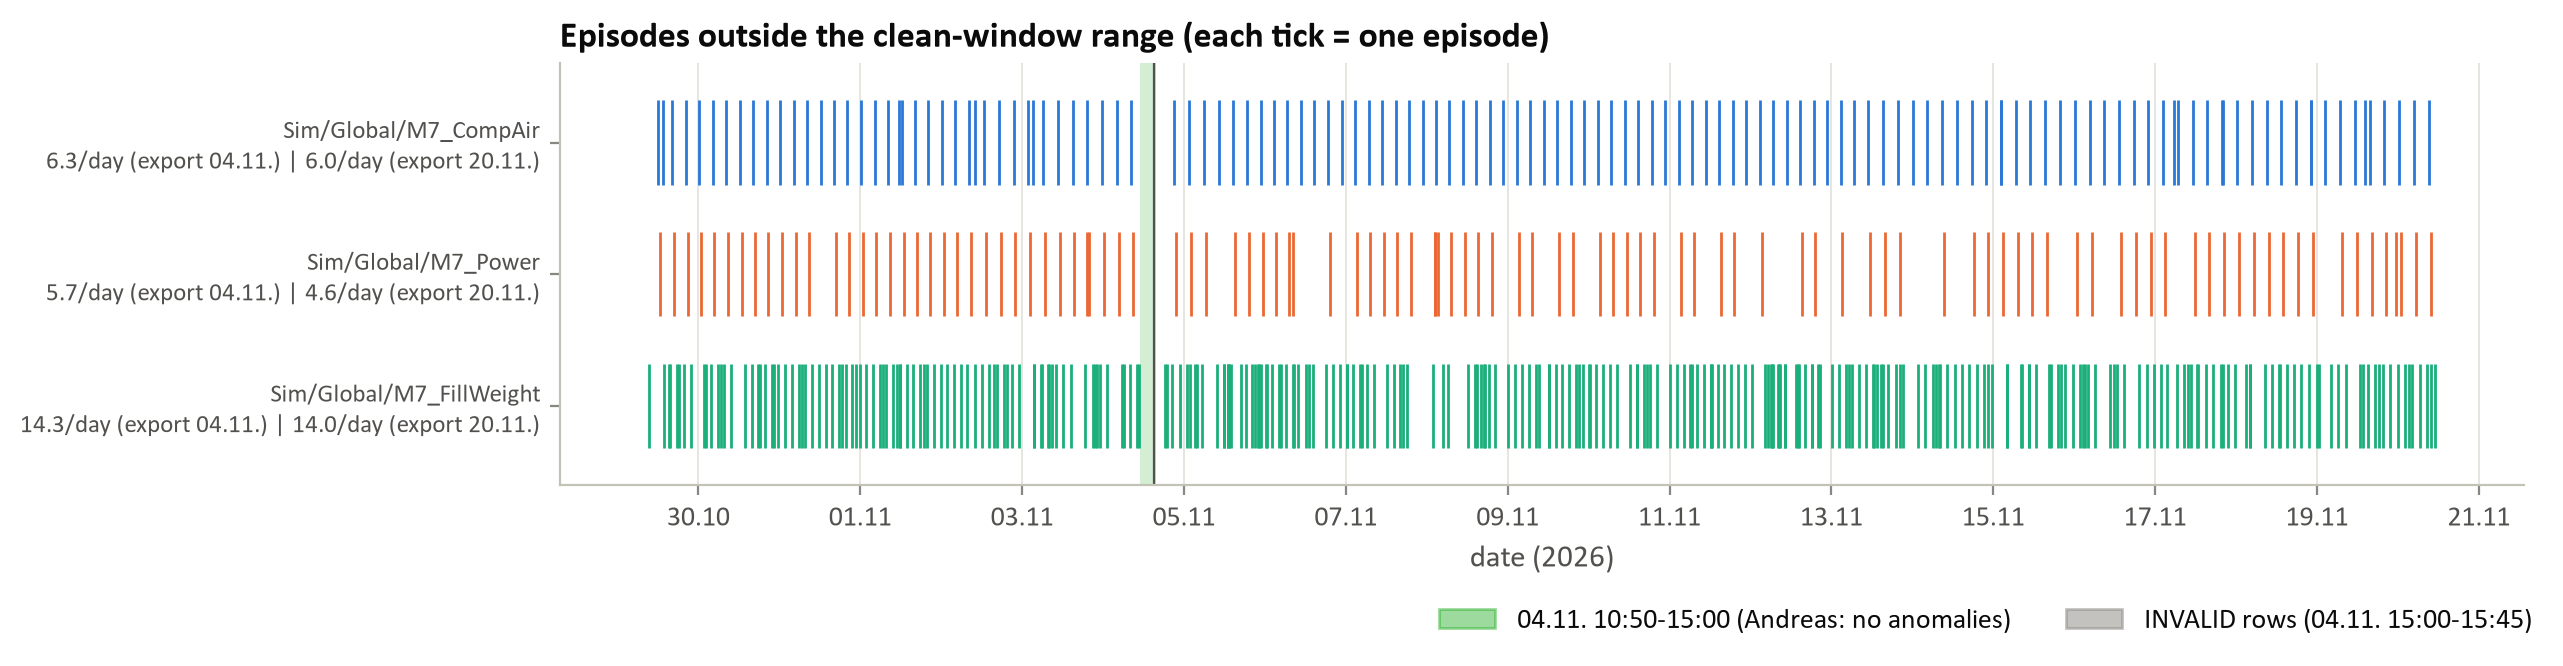

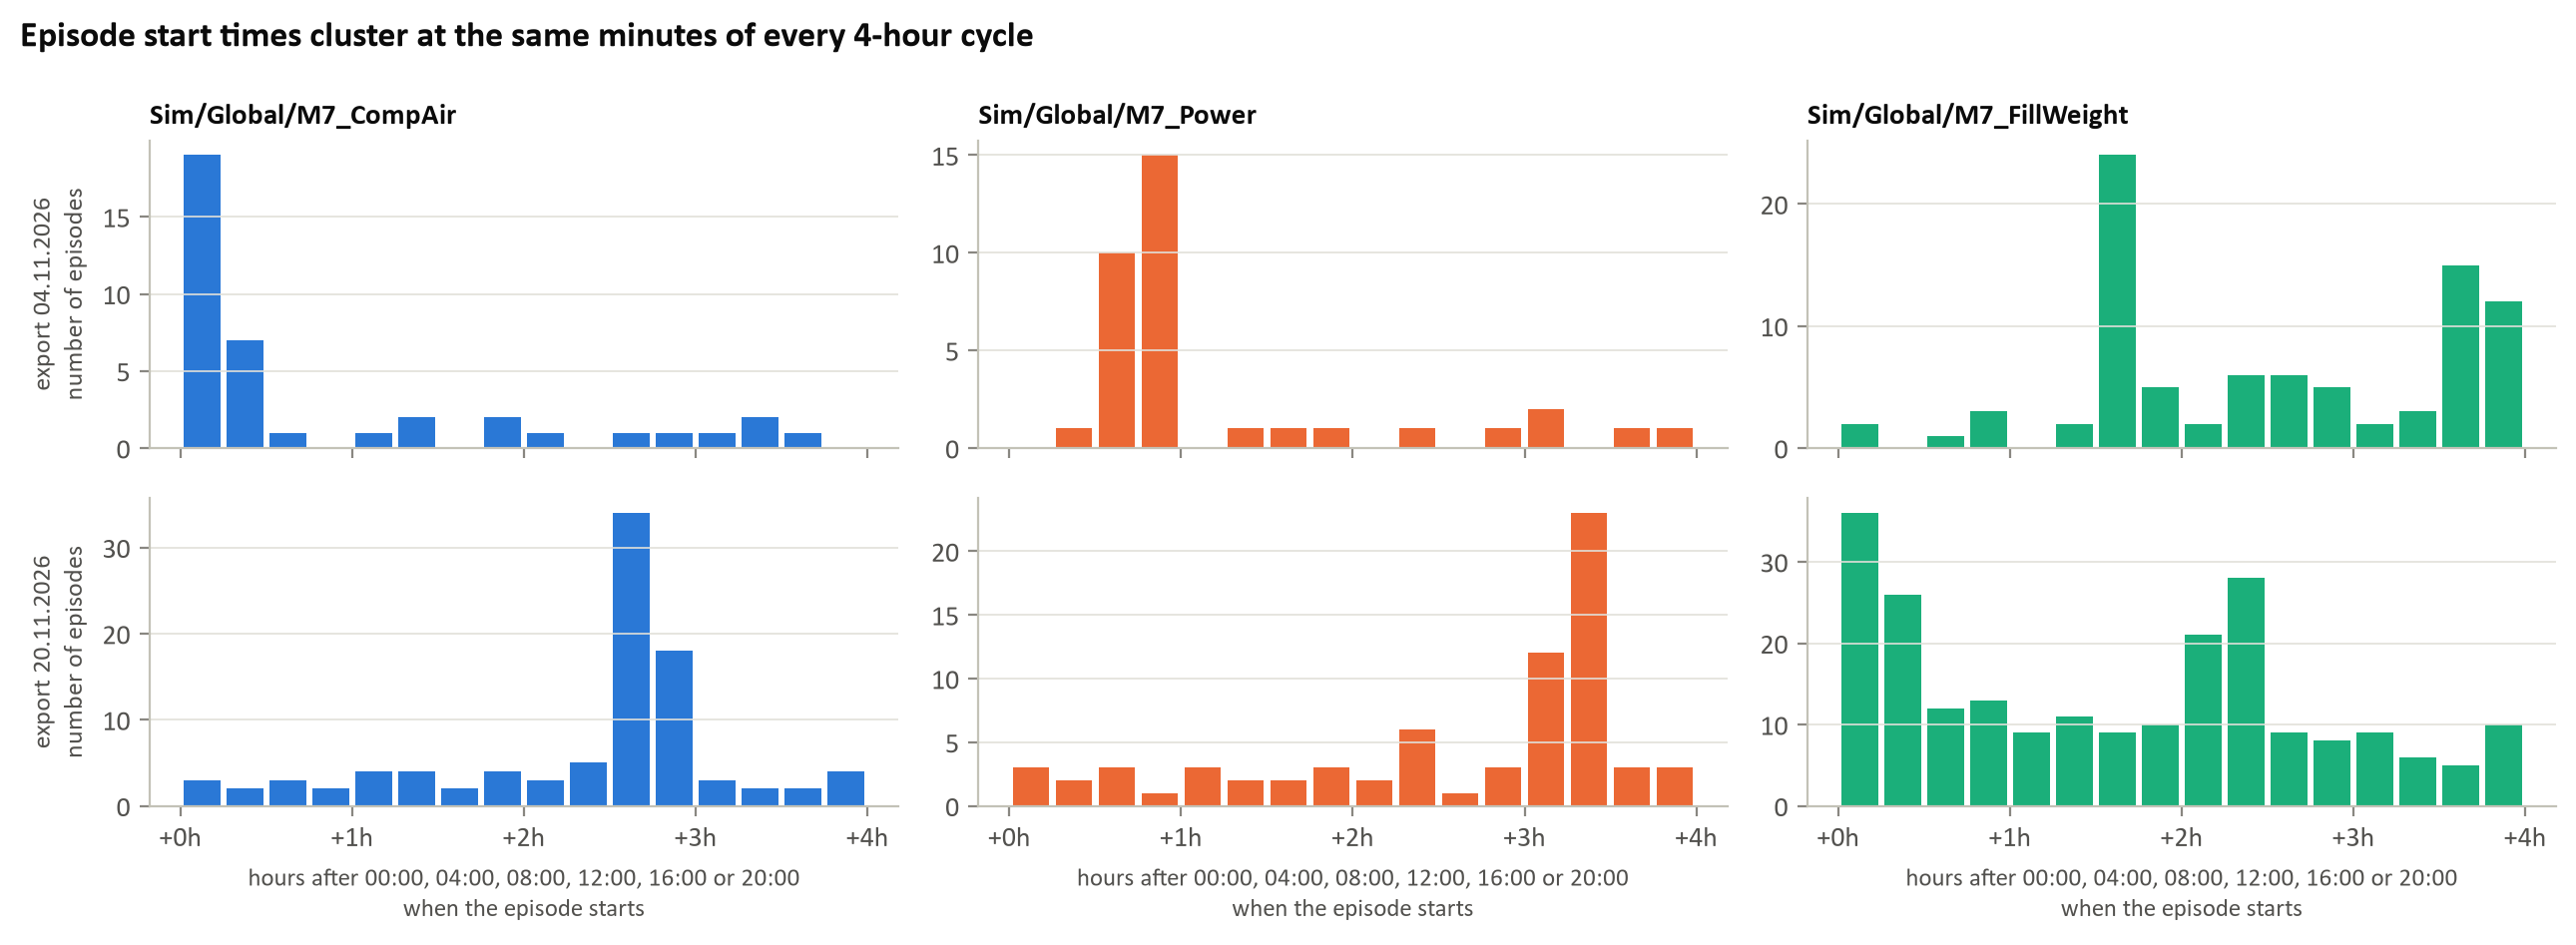

,export,variable,episodes,share starting in the busiest 30 min of the 4 h cycle %,busiest 30 min (h:mm after 00/04/08/12/16/20 h),if start times were random %
0,Export 04.11.2026 (cyclic 3 s),Sim/Global/M7_CompAir,39,66.666667,0:00-0:30,12.5
1,Export 04.11.2026 (cyclic 3 s),Sim/Global/M7_Power,35,71.428571,0:30-1:00,12.5
2,Export 04.11.2026 (cyclic 3 s),Sim/Global/M7_FillWeight,88,34.090909,1:34-2:04,12.5
3,Export 20.11.2026 (cyclic 10 s),Sim/Global/M7_CompAir,95,54.736842,2:19-2:49,12.5
4,Export 20.11.2026 (cyclic 10 s),Sim/Global/M7_Power,72,52.777778,3:03-3:33,12.5
5,Export 20.11.2026 (cyclic 10 s),Sim/Global/M7_FillWeight,222,29.729730,0:10-0:40,12.5


In [15]:
if "COPA_READY" not in globals(): raise RuntimeError("Please run the Start cell (top of the notebook) first.")
show("fig05_episodes_over_time.png")
show("fig10_episode_start_times_4h_cycle.png")
display(pd.read_csv(TAB / "episode_start_times_4h_cycle.csv"))

**What it shows:** before 10:50 there are 39 episodes of `Sim/Global/M7_CompAir`, 35 of `Sim/Global/M7_Power` and 88 of
`Sim/Global/M7_FillWeight` (162 in total); in 10:50-15:00 there are none. That is about 6.3, 5.7 and 14.3 per day; the
export of 20.11.2026 has nearly the same rates (6.0, 4.6 and 14.0 per day). The start times are not random: 67 % of the
compressed-air episodes start in the first 30 minutes of a 4-hour cycle and 71 % of the power episodes 30-60 minutes
after it (random would be 12.5 %). In the export of 20.11.2026 the same pattern appears, shifted by about 2.5 hours.

**What we can say:** *"We count 162 anomaly episodes in the labelled period and none in the clean window. They repeat on
a fixed 4-hour schedule, which suggests the simulation inserts them; the same schedule continues in the second export.
We would ask COPA-DATA for the list of inserted anomalies to confirm."*

## Step 9 · What do the anomalies cause?
**Question:** does an anomaly change anything else on the filler: more defective bottles, more compressed air or
power, or more failures afterwards?

**What data it uses:** both exports; the anomaly episodes of step 8 (`results/tables/episodes_outside_clean_range_*.csv`);
the bottle counters `Sim/Global/M7.Admin.ProductData_ProcessedCount` (all filled bottles of the current order) and
`Sim/Global/M7.Admin.ProductData_DefectiveCount` (rejects / scrap / defective bottles of the current order); the machine
state `M07.WS_Cur_State` (1024 = Equipment Failure).

**What it does:**
1. *Defective bottles:* both counters grow with every bottle. The increase from one row to the next is the number of
   bottles filled, and found defective, in those 3 seconds. These are added up inside the episodes of each variable and
   in normal running, giving defective bottles per 1,000 filled bottles. (When a new order starts, the counters go back
   to 0; those rows are skipped.)
2. *Extra consumption:* the average of `Sim/Global/M7_CompAir` and `Sim/Global/M7_Power` inside their episodes compared
   with normal running.
3. *Failures afterwards:* how often an Equipment Failure follows within 10 minutes after the end of an episode, compared
   with how often one follows within 10 minutes after any normal running moment (the background rate).

**How to read the result:** table 1 and the bar chart: defective bottles per 1,000 filled bottles (bar height) in each
situation (x-axis). Table 2: average value while running, how many % higher it is inside the episodes, how much of the
running time the episodes cover, and the extra consumption over the whole anomaly period. Table 3: % of the episodes
followed by an Equipment Failure within 10 minutes; the last row is the background rate.

**1 · Defective bottles per 1,000 filled bottles, machine running**

,export of 04.11.2026,export of 20.11.2026
inside Sim/Global/M7_FillWeight episodes,116.4,132.2
inside Sim/Global/M7_CompAir episodes,39.4,39.3
inside Sim/Global/M7_Power episodes,39.3,40.1
normal running (no episode),46.0,47.4
clean window 10:50-15:00,40.2,NaN


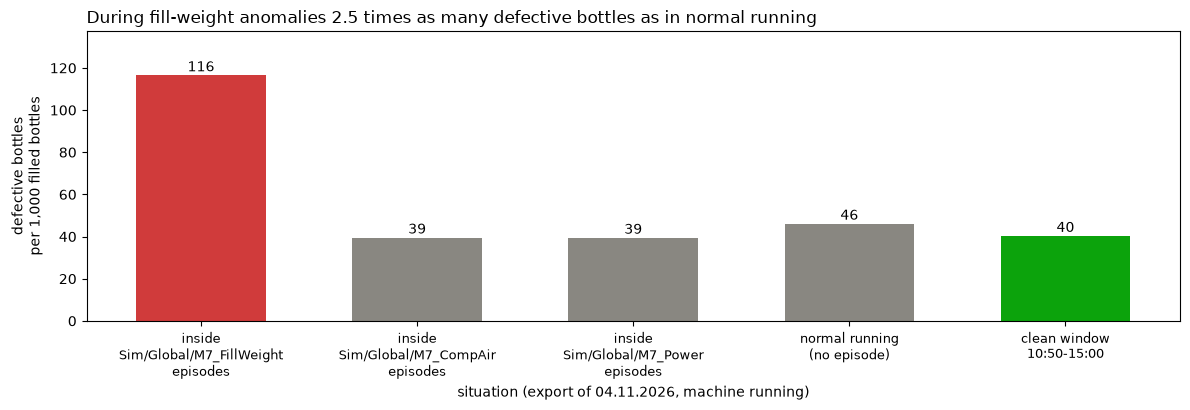

**2 · Compressed air and power while running** (export of 04.11.2026; normal running = before 10:50 outside episodes)

,average inside its episodes,average in normal running,average in clean window,higher inside episodes %,running time inside episodes %,extra over the whole anomaly period %
variable,,,,,,
Sim/Global/M7_CompAir,31.59,28.63,28.62,10.3,2.5,0.26
Sim/Global/M7_Power,10.66,9.79,9.78,8.8,2.8,0.25


**3 · % followed by an Equipment Failure (`M07.WS_Cur_State` = 1024) within 10 minutes**

,export of 04.11.2026,export of 20.11.2026
after the end of a Sim/Global/M7_FillWeight episode,44,34
after the end of a Sim/Global/M7_CompAir episode,41,26
after the end of a Sim/Global/M7_Power episode,34,38
after any normal running moment (background rate),31,32


In [16]:
if "COPA_READY" not in globals(): raise RuntimeError("Please run the Start cell (top of the notebook) first.")
VARS = ["Sim/Global/M7_FillWeight", "Sim/Global/M7_CompAir", "Sim/Global/M7_Power"]
FILLED = "Sim/Global/M7.Admin.ProductData_ProcessedCount"
DEFECTIVE = "Sim/Global/M7.Admin.ProductData_DefectiveCount"

def episode_rows(w, export):              # True for every row inside an episode of that variable (episodes of step 8)
    eps = pd.read_csv(TAB / f"episodes_outside_clean_range_{export}.csv", parse_dates=["start", "end"])
    inside = {v: pd.Series(False, index=w.index) for v in VARS}
    for _, e in eps.iterrows():
        inside[e["variable"]].loc[e["start"]:e["end"]] = True
    return eps, inside

def situations(w, inside, labelled):
    s = {f"inside {v} episodes": inside[v] for v in VARS}
    no_episode = ~(inside[VARS[0]] | inside[VARS[1]] | inside[VARS[2]])
    s["normal running (no episode)"] = no_episode & (w.index < CLEAN_START) if labelled else no_episode
    if labelled:
        s["clean window 10:50-15:00"] = pd.Series(w.index >= CLEAN_START, index=w.index)
    return s

def defective_per_1000(w, sits):
    run = w[SPEED].isin([990, 1089])
    filled, defective = w[FILLED].diff(), w[DEFECTIVE].diff()     # bottles since the previous row
    ok = run & (filled >= 0) & (defective >= 0)                   # skip rows where a new order starts (counters back to 0)
    return pd.Series({k: round(1000 * defective[m & ok].sum() / filled[m & ok].sum(), 1) for k, m in sits.items()})

w1, w2 = wide_table("261104"), wide_table("261120")
eps1, in1 = episode_rows(w1, "export_2026-11-04")
eps2, in2 = episode_rows(w2, "export_2026-11-20")
s1, s2 = situations(w1, in1, labelled=True), situations(w2, in2, labelled=False)

t1 = pd.DataFrame({"export of 04.11.2026": defective_per_1000(w1, s1), "export of 20.11.2026": defective_per_1000(w2, s2)})
t1 = t1.reindex(list(s1))                 # keep the order: three kinds of episodes, normal running, clean window
display(Markdown("**1 · Defective bottles per 1,000 filled bottles, machine running**"))
display(t1)

rates = t1["export of 04.11.2026"]
fig, ax = plt.subplots(figsize=(12, 4.2))
colors = ["#d03b3b" if "FillWeight" in k else "#0ca30c" if "clean" in k else "#898781" for k in rates.index]
ax.bar(range(len(rates)), rates, color=colors, width=0.6)
ax.set_ylim(0, rates.max() * 1.18)
for i, r in enumerate(rates):
    ax.text(i, r + 2, f"{r:.0f}", ha="center", fontsize=10)
ax.set_xticks(range(len(rates)), [k.replace("inside ", "inside\n").replace(" episodes", "\nepisodes")
                                   .replace(" (no", "\n(no").replace(" 10:50", "\n10:50") for k in rates.index], fontsize=9)
ax.set_ylabel("defective bottles\nper 1,000 filled bottles")
ax.set_xlabel("situation (export of 04.11.2026, machine running)")
ratio = rates["inside Sim/Global/M7_FillWeight episodes"] / rates["normal running (no episode)"]
ax.set_title(f"During fill-weight anomalies {ratio:.1f} times as many defective bottles as in normal running", loc="left")
plt.tight_layout(); plt.show()

# 2 · compressed air and power inside their episodes (export of 04.11.2026)
run, before = w1[SPEED].isin([990, 1089]), w1.index < CLEAN_START
normal = s1["normal running (no episode)"]
rows = []
for v in ["Sim/Global/M7_CompAir", "Sim/Global/M7_Power"]:
    during, usual = w1.loc[run & in1[v], v], w1.loc[run & normal, v]
    rows.append({"variable": v,
                 "average inside its episodes": round(during.mean(), 2),
                 "average in normal running": round(usual.mean(), 2),
                 "average in clean window": round(w1.loc[run & ~before, v].mean(), 2),
                 "higher inside episodes %": round(100 * (during.mean() / usual.mean() - 1), 1),
                 "running time inside episodes %": round(100 * len(during) / (run & before).sum(), 1),
                 "extra over the whole anomaly period %": round(100 * (during - usual.mean()).sum() / w1.loc[run & before, v].sum(), 2)})
display(Markdown("**2 · Compressed air and power while running** (export of 04.11.2026; normal running = before 10:50 outside episodes)"))
display(pd.DataFrame(rows).set_index("variable"))

# 3 · does an Equipment Failure (M07.WS_Cur_State = 1024) follow within 10 minutes?
def failure_after(w, eps, sits, export_code):
    raw = raw_rows()
    st = raw[~raw["INVALID"] & raw["file"].str.match(f"07{export_code}") & (raw["Variable name"] == "M07.WS_Cur_State")]
    failures = pd.DatetimeIndex(st.loc[st["value"] == 1024, "timestamp"].sort_values())
    ten = pd.Timedelta(minutes=10)
    out = {}
    for v in VARS:
        ends = eps.loc[eps["variable"] == v, "end"]
        out[f"after the end of a {v} episode"] = int(round(100 * np.mean([((failures > t) & (failures <= t + ten)).any() for t in ends])))
    soon = pd.Series(False, index=w.index)                        # rows with a failure in the next 10 minutes
    for t in failures:
        soon.loc[t - ten:t - pd.Timedelta(seconds=1)] = True
    normal = sits["normal running (no episode)"] & w[SPEED].isin([990, 1089])
    out["after any normal running moment (background rate)"] = int(round(100 * soon[normal].mean()))
    return pd.Series(out)

t3 = pd.DataFrame({"export of 04.11.2026": failure_after(w1, eps1, s1, "261104"),
                   "export of 20.11.2026": failure_after(w2, eps2, s2, "261120")})
display(Markdown("**3 · % followed by an Equipment Failure (`M07.WS_Cur_State` = 1024) within 10 minutes**"))
display(t3)

**What it shows (measured in the data):**
* **Fill-weight anomalies cost bottles.** While they last, 116 of 1,000 filled bottles are counted as defective,
  against 46 in normal running and 40 in the clean window: about 2.5 times as many. The export of 20.11.2026 shows the
  same (132 against 47). The bottles with a wrong fill weight end up in `DefectiveCount` (rejects / scrap).
* **Compressed-air and power anomalies cost a little energy, not bottles.** Inside them the share of defective bottles
  is normal (39-40 per 1,000). The filler needs about 10 % more compressed air (31.59 instead of 28.63) or about 9 %
  more power (10.66 instead of 9.79). Because the episodes cover only 2.5-2.8 % of the running time, the extra
  consumption over the whole anomaly period is only about 0.25 %.
* **No consistent link to failures.** In the export of 04.11.2026 an Equipment Failure follows within 10 minutes after
  34-44 % of the episodes, somewhat more often than after any normal running moment (31 %); in the export of 20.11.2026
  it is 26-38 % against 32 %, so no difference there. Equipment failures happen about twice per hour all the time, also
  in the clean window (step 3). The data therefore shows no consistent sign that the anomalies lead to failures.

**What it could mean in a real filler (our interpretation, not measured in this data):** the task is about *"early
warning of plant failures"* (task PDF slide 7), and Andreas wrote that *"there should be anomalies that show signs of
degradation"*. In this simulation no failure follows, but in a real plant the same patterns would be warning signs:
* *Compressed air need rising while the speed stays the same:* typical reasons are leaks or worn seals and valves in
  the pneumatics. If it goes on: higher energy costs, valves that react more slowly, and in the end a stop of the filler.
* *Power need rising while the speed stays the same:* typical reasons are more friction, e.g. in worn bearings, chains
  or the drive. If it goes on: higher energy costs, overheating, and in the end a breakdown of the drive (unplanned
  downtime).
* *Fill weight jumping far from 500:* typical reasons are problems with dosing or the filling valves. Effects: rejected
  bottles (as seen in the data), product given away in overfilled bottles, and underfilled bottles reaching customers
  if a check fails.

These reasons are general engineering knowledge; the data cannot show them. To confirm them we would ask COPA-DATA
which degradation scenarios they simulated: the task says the test environment uses *"a documented degradation model"*
(task PDF slide 8).

**What we can say:** *"The fill-weight anomalies cost money right away: they more than double the share of defective
bottles. The compressed-air and power anomalies cost little energy and show no consistent link to failures in this
simulation, but they are the kind of slow rise that announces wear in a real machine, which is exactly what an
early-warning system should catch."*

## Step 10 · The three research questions: first answers
The three questions are from the task PDF (slide 9). All answers use the export of 04.11.2026 and Andreas' label and
are first, preliminary answers. The numbers come from `results/` (made by step 8).

### Research question 1: detection methods
*"How effectively do methods of varying complexity (statistical baseline, Isolation Forest, autoencoder, LSTM-based)
detect defined degradation scenarios in zenon archive data? Measured in terms of event-based precision/recall, false
alarms per operating day and lead time before failure."*

**Short answer:** simple methods already work on this data. All three methods we tested raise no false alarm in the
clean window. The best warning comes from comparing 60-second averages with the normal range: about 6 minutes (342 s)
before an anomaly reaches its peak. Ranking the values by how often they occur finds 59 % of the episodes but warns only
about 40 s before the peak; Isolation Forest finds 49 % and warns about 3 minutes (176 s) before. The reference
episodes come from the range method itself, so exact precision and recall need COPA-DATA's list of inserted anomalies.
Autoencoder and LSTM are the next step.

**What data it uses:** export of 04.11.2026; reference = the 162 episodes of step 8.

**What it does:** compares three methods. *Rare values* = step 7 applied to all three variables. *Outside
clean-window range* = step 8; it defines the reference, so it scores 100 % by construction. *Isolation Forest* = a
standard machine-learning method that separates unusual combinations of values; it flags 1 % of the rows.

**How to read the result:** "episodes detected %" is like recall: share of the 162 episodes with at least one alarm.
"alarms that hit an episode %" is like precision: share of the alarms that fall on an episode. "false alarms per day" =
alarms in the clean window, scaled to 24 h (one alarm there = 5.8 per day, because the window is only 4.17 h).
"median warning before peak s" = how many seconds before an episode reaches its highest point the first alarm comes; we
use it instead of "lead time before failure", because no failures follow the anomalies in this data.

**RQ1: three methods**

,method,flagged rows %,alarm events until 04.11. 10:50,alarm events 04.11. 10:50-15:00,alarm events per hour until 10:50,alarm events per hour 10:50-15:00,false alarms per day,clean hours,anomaly hours,episodes detected %,median delay s,alarms that hit an episode %,median warning before peak s,episodes detected % | Sim/Global/M7_CompAir,episodes detected % | Sim/Global/M7_Power,episodes detected % | Sim/Global/M7_FillWeight
0,"rare values (< 1 in 10,000 rows)",0.39,165,0,1.11,0.0,0.0,4.17,148.0,59.26,0.0,83.03,40.5,41.03,17.14,84.09
1,outside clean-window range,7.21,194,0,1.31,0.0,0.0,4.17,148.0,100.00,0.0,100.00,342.0,100.00,100.00,100.00
2,Isolation Forest,0.94,96,0,0.65,0.0,0.0,4.17,148.0,49.38,154.5,100.00,175.5,58.97,65.71,38.64


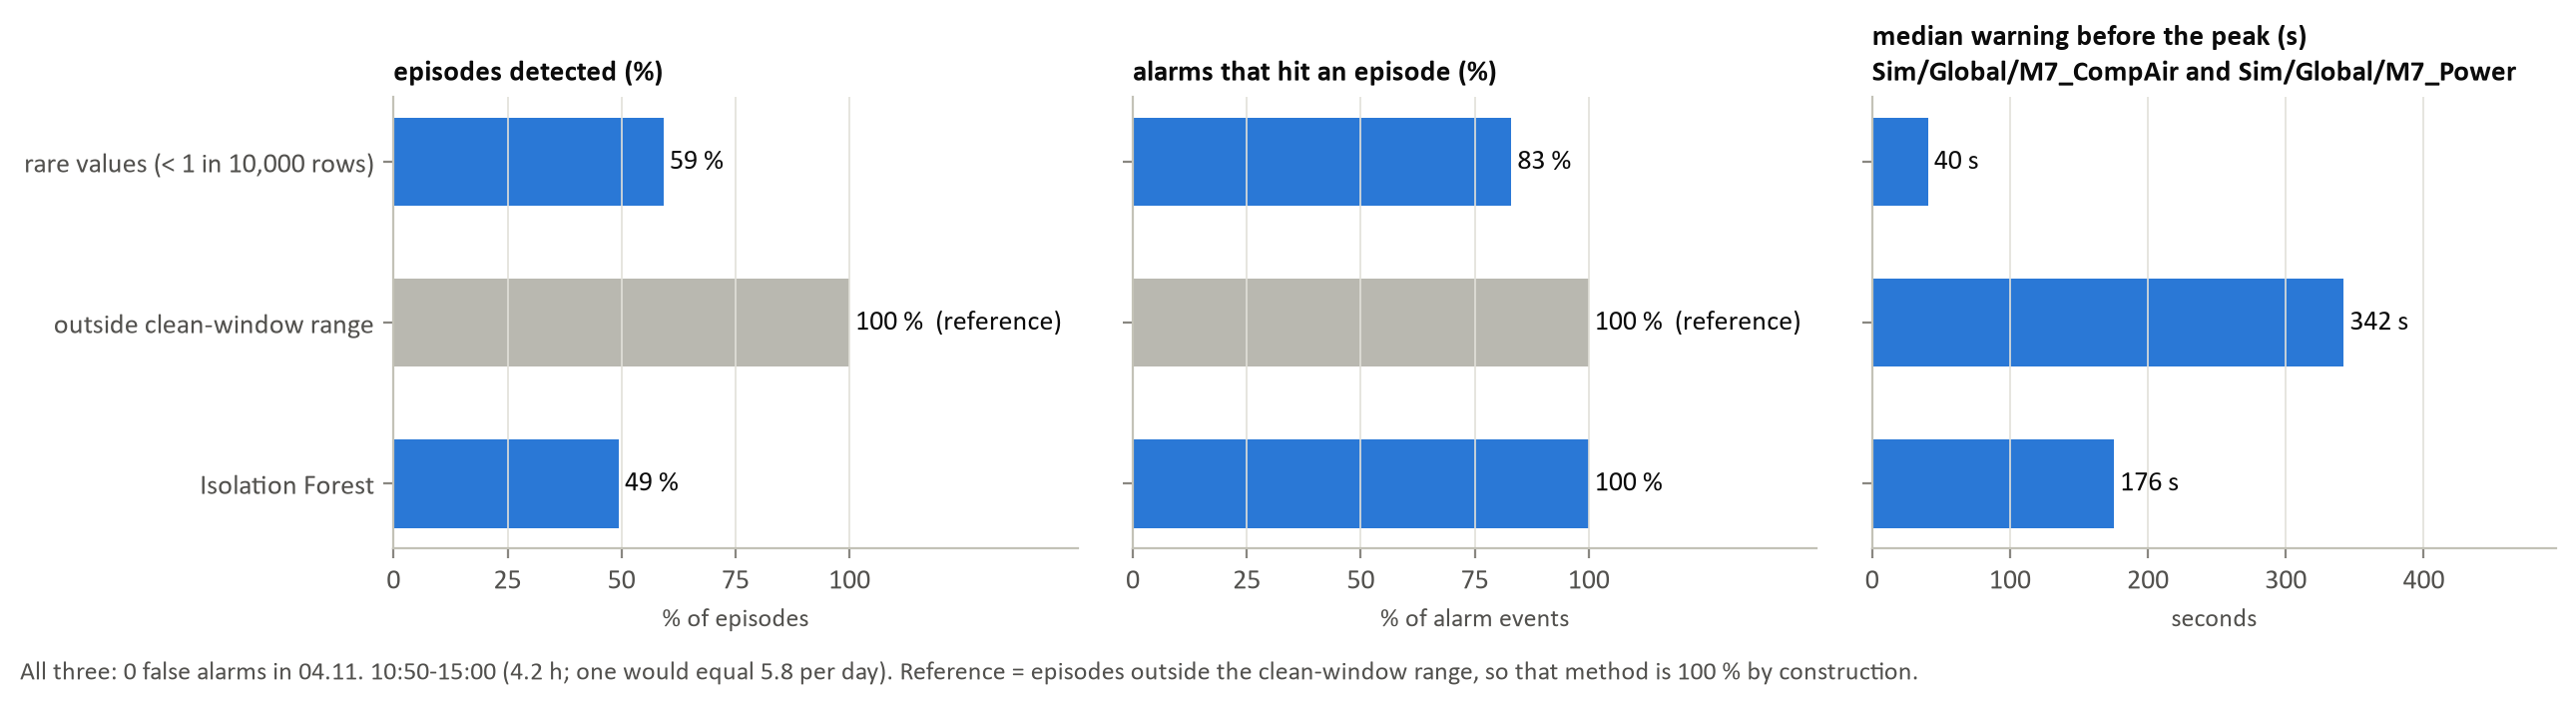

In [17]:
if "COPA_READY" not in globals(): raise RuntimeError("Please run the Start cell (top of the notebook) first.")
display(Markdown("**RQ1: three methods**"))
display(pd.read_csv(TAB / "rq1_methods.csv").round(2))
show("fig06_rq1_methods.png")

**What it shows:** all three methods give 0 false alarms in the clean window. *Rare values* find 59 % of the
episodes and 83 % of their alarms hit an episode, but they warn only about 40 s before the peak. *Outside clean-window
range* with 60-second rolling values warns about 342 s (about 6 minutes) before the peak. *Isolation Forest* finds 49 %,
all of its alarms hit an episode, and it warns 176 s before the peak. Autoencoder and LSTM are not evaluated yet.

**What we can say:** *"Simple statistical methods already separate the anomaly period from normal operation without
false alarms; looking at 60-second averages instead of single values gives several minutes of warning before an anomaly
peaks. Autoencoder and LSTM come next."*

### Research question 2: batch vs. online
*"How do detection quality, latency and false alarm rate change when switching from batch analysis to online detection
on the data stream?"*

**Short answer:** only a little. Seeing only past data, as it would live on the data stream, the method still finds
100 % (compressed air), 92 % (power) and 96 % (fill weight) of the episodes that the batch analysis finds, at most about
30 s later, and the false alarms stay at zero. We tested this by replaying the export, not yet on a live zenon connection.

**What "online" means:** the task's word for detecting anomalies live, while the data arrives (task PDF slide 8:
*"First evaluate model offline on exported archive data, second implement online detection with zenon OPC UA Server"*).
Online, a method only knows the past. *Batch* analyses the complete exported file afterwards and may also use later rows.

**What data it uses / what it does:** no live connection and nothing downloaded: we replayed the export of 04.11.2026
row by row. The online version uses a 60-second window of past rows only; the batch version uses a centred 60-second
window (30 s before and 30 s after each row). Both use the limits of the clean window.

**How to read the result:** per variable: share of the batch episodes that the online version also finds, and the
median extra delay of the online version in seconds.

**RQ2: online (only past values) vs. batch (centred window)**

,variable,batch episodes,batch episodes also found online %,median extra delay online s,p90 extra delay online s
0,Sim/Global/M7_CompAir,36,100.0,0.0,9.0
1,Sim/Global/M7_Power,38,92.1,30.0,30.0
2,Sim/Global/M7_FillWeight,91,95.6,30.0,30.0


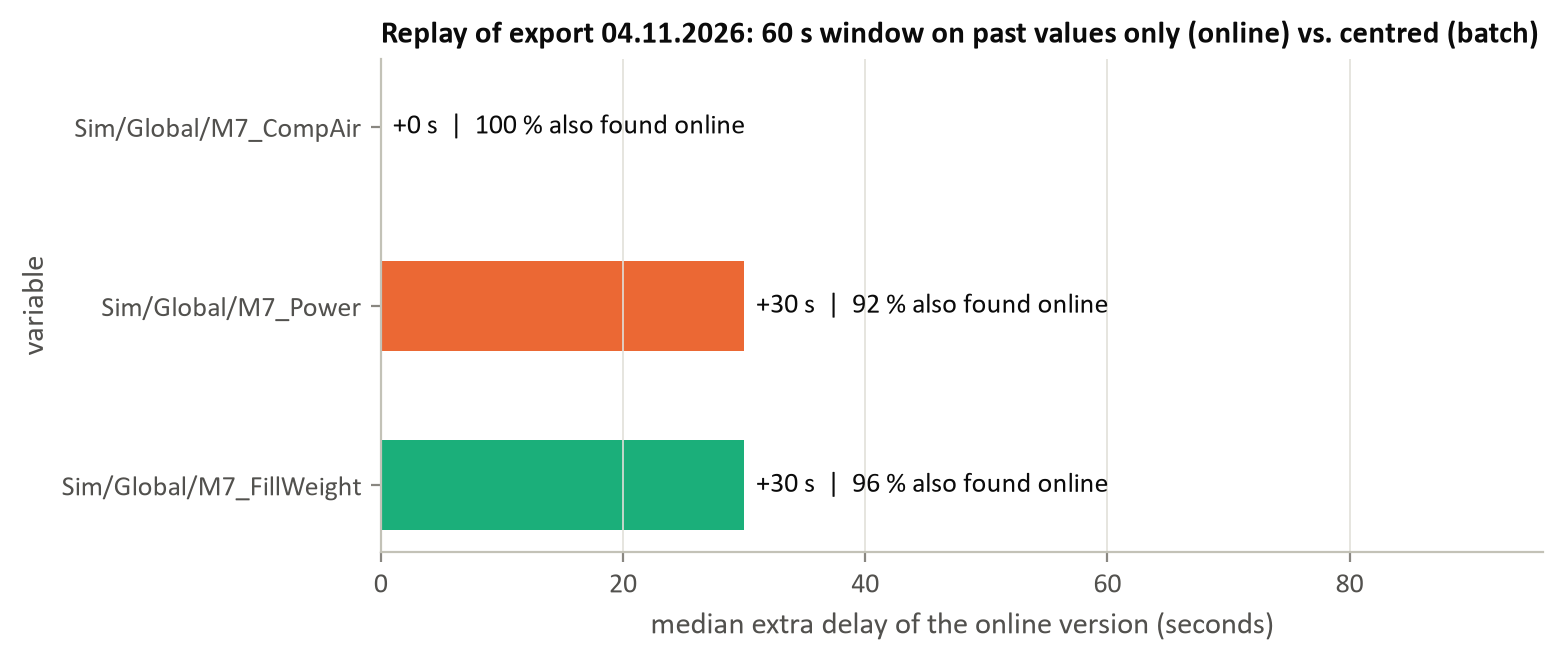

In [18]:
if "COPA_READY" not in globals(): raise RuntimeError("Please run the Start cell (top of the notebook) first.")
display(Markdown("**RQ2: online (only past values) vs. batch (centred window)**"))
display(pd.read_csv(TAB / "rq2_online_vs_batch.csv").round(1))
show("fig07_rq2_online_vs_batch.png", width=800)

**What it shows:** online finds 100 % (`Sim/Global/M7_CompAir`), 92 % (`Sim/Global/M7_Power`) and 96 %
(`Sim/Global/M7_FillWeight`) of the batch episodes. It is about 30 s later for power and fill weight (half the 60-second
window) and not later for compressed air. False alarms in the clean window: 0 in both versions.

**What we can say:** *"Switching from batch to online costs about half the averaging window in delay (here 30 s) and
loses a few percent of the episodes; false alarms stay at zero. A live test on the zenon OPC UA stream is the next step."*

### Research question 3: archive settings
*"How do zenon archiving parameters (sampling interval, recording on change, hysteresis, compression) influence the
achievable lead time? Which configuration is recommended for PdM-compatible archives?"*

**Short answer:** for early warning, archive the three process values cyclically every 3 s, or on change with a small
hysteresis of about 0.5. The fill-weight anomalies are the most sensitive: at 9 s 33 % of them are missed, at 60 s
75 %, and at 60 s all warnings come about 1-3 minutes later. A hysteresis of 0.5 stores only 40-56 % of the rows and
still finds at least 97 % of the episodes; 2.0 is too coarse (power: 34 % found). The export of 20.11.2026 uses 10 s,
which is already too coarse for the fill weight. Compression was not tested yet.

**What data it uses / what it does:** the export of 04.11.2026 (3 s). (1) *Sampling interval:* keep only every 2nd,
3rd, 5th, 10th or 20th row (= 6, 9, 15, 30, 60 s) and check how many of the episodes found at 3 s are still found, and
how much later. (2) *Recording on change with hysteresis:* replay each variable as if zenon stored a new row only when
the value changes by more than the hysteresis; count the stored rows and the episodes still found.

**How to read the result:** sampling figure: x-axis = sampling interval in seconds; y-axis = % of the 3 s episodes still
found (left) and median delay until the first flag (right); one line per variable. Hysteresis figure: x-axis =
hysteresis (minimum change before a new row is stored, in the variable's own units); y-axis = rows stored compared with
cyclic 3 s (left) and episodes still found (right).

**RQ3: sampling interval and recording on change**

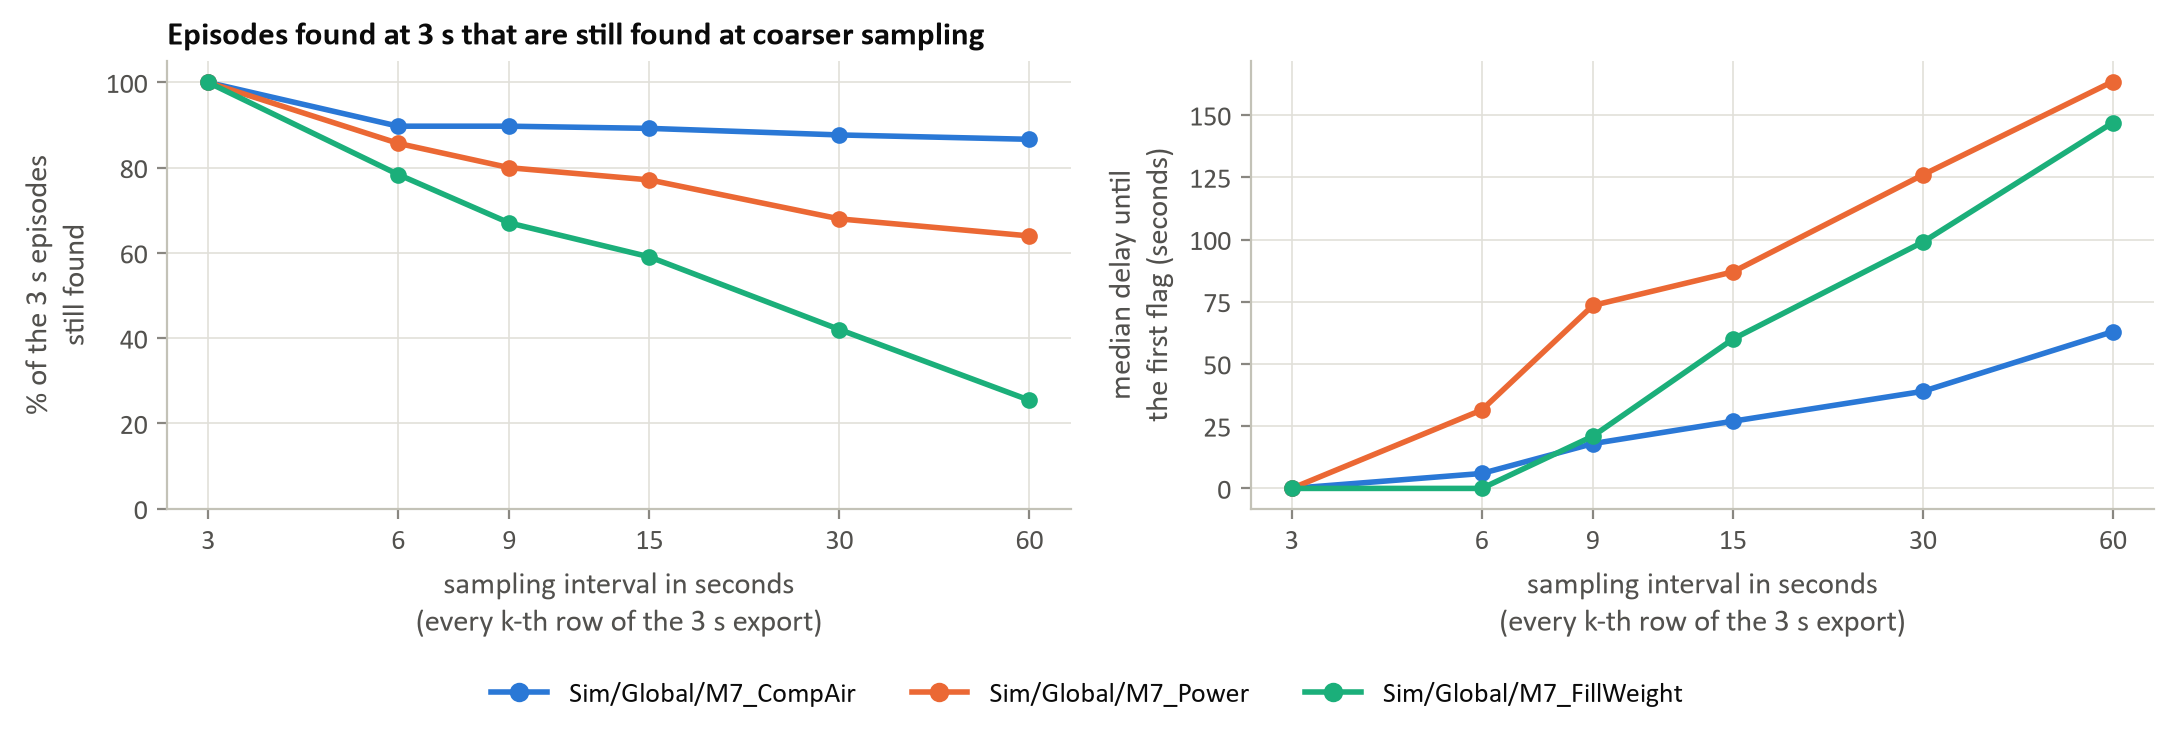

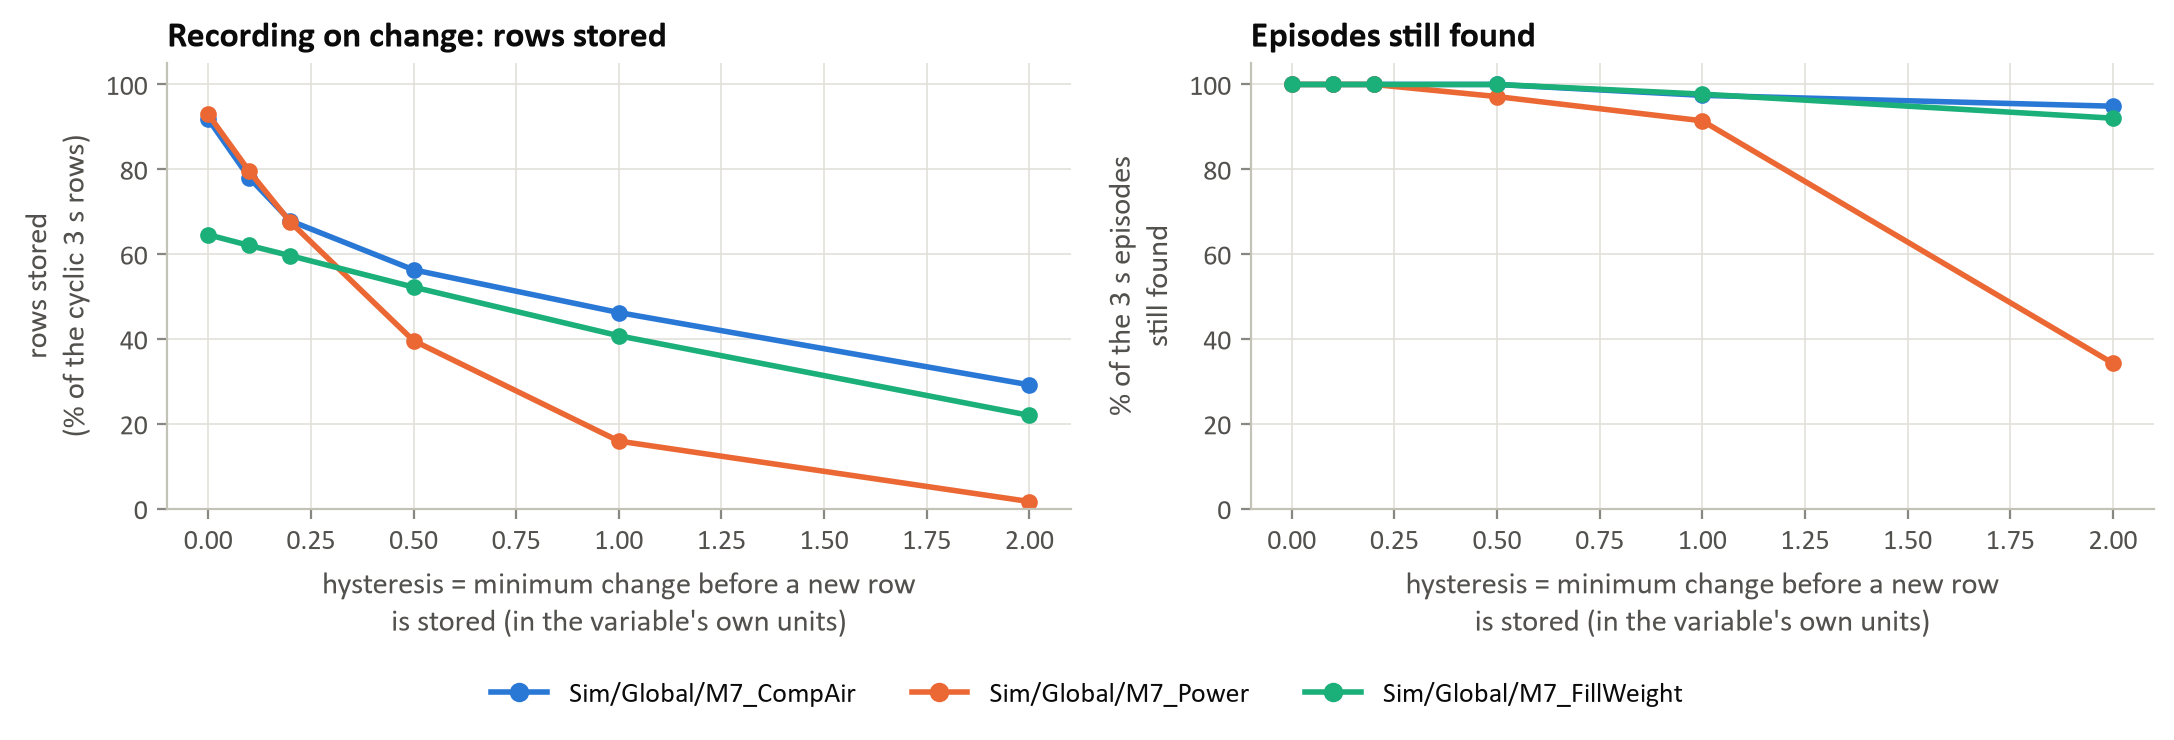

,interval s,variable,phase offsets averaged,detected %,median delay s,rows per day per variable
0,3,Sim/Global/M7_CompAir,1,100.0,0.0,28800.0
1,3,Sim/Global/M7_Power,1,100.0,0.0,28800.0
2,3,Sim/Global/M7_FillWeight,1,100.0,0.0,28800.0
3,6,Sim/Global/M7_CompAir,2,89.7,6.0,14400.0
4,6,Sim/Global/M7_Power,2,85.7,31.5,14400.0
5,6,Sim/Global/M7_FillWeight,2,78.4,0.0,14400.0
6,9,Sim/Global/M7_CompAir,3,89.7,18.0,9600.0
7,9,Sim/Global/M7_Power,3,80.0,73.5,9600.0
8,9,Sim/Global/M7_FillWeight,3,67.0,21.0,9600.0
9,15,Sim/Global/M7_CompAir,5,89.2,27.0,5760.0


In [19]:
if "COPA_READY" not in globals(): raise RuntimeError("Please run the Start cell (top of the notebook) first.")
display(Markdown("**RQ3: sampling interval and recording on change**"))
show("fig08_rq3_sampling_interval.png")
show("fig09_rq3_hysteresis.png")
display(pd.read_csv(TAB / "rq3_sampling_interval.csv").round(1))

**What it shows:** the fill-weight episodes need fast sampling: 100 % found at 3 s, 67 % at 9 s, 25 % at 60 s.
Compressed-air episodes stay at 87 % or more even at 60 s; power drops to 64 %. The delay grows to 63-164 s at 60 s.
Recording on change without hysteresis stores almost every row for compressed air and power (92-93 %), because their
values change a little every time; a hysteresis of 0.5 stores only 40-56 % of the rows and still finds at least 97 % of the
episodes; 2.0 is too coarse for power (34 % found).

**What we can say:** *"For anomaly detection the process values should be archived every 3 s (the finest we could
test) or on change with a small hysteresis of about 0.5. Already at 9 s a third of the fill-weight anomalies would be
missed (the second export uses 10 s). We measured this by thinning and replaying the real 3 s export, not in zenon itself."*

## Step 11 · Explore yourself
**What it does:** draws any variable for any time window you choose, with `Sim/Global/M7.Status.CurMachSpeed` below.

**How to use it:** set `VARIABLE`, `START` and `END` (format `YYYY-MM-DD HH:MM`) and press ▶ again; zoom with the mouse.
In the browser version of Colab the fields appear as a form. Good windows to start with: 2026-10-30 20:00 to 20:30
(compressed air), 2026-11-03 06:35 to 07:00 (power), 2026-11-04 10:00 to 10:20 (fill weight),
2026-11-04 12:00 to 12:30 (Andreas' clean window).

In [ ]:
# @title Explorer
VARIABLE = "Sim/Global/M7_CompAir"   # @param ["Sim/Global/M7_CompAir", "Sim/Global/M7_Power", "Sim/Global/M7_FillWeight", "Sim/Global/M7.Admin.ProductData_DefectiveCount", "Sim/Global/M7.Status.StateCurrent"]
START = "2026-10-30 20:00"           # @param {type:"string"}
END = "2026-10-30 20:30"             # @param {type:"string"}

if "COPA_READY" not in globals(): raise RuntimeError("Please run the Start cell (top of the notebook) first.")
import plotly.graph_objects as go
from plotly.subplots import make_subplots
w = wide_table("261104") if pd.Timestamp(START) < pd.Timestamp("2026-11-04 15:00") else wide_table("261120")
s = w.loc[START:END]
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, row_heights=[0.7, 0.3], subplot_titles=[VARIABLE, SPEED])
fig.add_trace(go.Scatter(x=s.index, y=s[VARIABLE], mode="lines+markers", marker=dict(size=3), line=dict(width=1)), row=1, col=1)
fig.add_trace(go.Scatter(x=s.index, y=s[SPEED], mode="lines", line=dict(width=1, color="#898781")), row=2, col=1)
fig.update_layout(height=600, showlegend=False, template="simple_white", title=f"{START} to {END} ({s['Andreas label'].iloc[0]})")
fig.update_yaxes(title_text=f"value of {VARIABLE}", row=1, col=1)
fig.update_yaxes(title_text="CurMachSpeed value", row=2, col=1)
fig.update_xaxes(title_text="time", row=2, col=1)
fig.show()

## In short: what we did, in six sentences
1. We used the six raw zenon files from COPA-DATA (simulated bottle filler M7, 29.10.-20.11.2026) exactly as delivered and only dropped the INVALID rows.
2. Using Andreas' statement, we compared his anomaly period (until 04.11. ~10:50) with his anomaly-free window (10:50-15:00).
3. Three measurements of the filler differ: `Sim/Global/M7_CompAir` and `Sim/Global/M7_Power` slowly rise above their normal level for a few minutes, and `Sim/Global/M7_FillWeight` jumps far away from 500; the machine states do not differ.
4. The fill-weight anomalies more than double the share of defective bottles while they last; the compressed-air and power anomalies cost a little extra energy and show no consistent link to failures in this simulation.
5. Simple rules, the ranking of values by frequency and Isolation Forest all find the anomalies without false alarms in the clean window, also when they only see past data (online); the anomalies repeat on a 4-hour schedule and continue in the second export.
6. For archiving, 3 s (or on change with a small hysteresis of about 0.5) keeps the anomalies visible; coarser sampling loses the short fill-weight anomalies first.